In [1]:
import re
import string

import requests
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder

import tiktoken
from transformers import BertTokenizer, GPT2TokenizerFast

from sklearn.linear_model import LinearRegression

# text to numbers

In [2]:
sentences = [
    "Whales are mammals not fish",
    "Despite the storm the ferry departed on schedule",
    "Why does time seem to slow down when youre bored",
    "Quantum computers exploit superposition to process information",
    "The old lighthouse has guided sailors for over a century",
    "Never underestimate the power of a well placed comma",
    "If prices keep rising demand will eventually fall",
    "Bees communicate the location of food through an intricate dance",
    "He didnt just win the race he shattered the record",
    "In 1969 humans first set foot on the Moon",
    "The recipe calls for two cups of flour and a pinch of salt",
    "Some algorithms scale linearly others scale exponentially",
    "The children laughed as the puppy chased its tail",
    "Silence in this context spoke louder than words",
    "The bridge swayed gently under the weight of the crowd"
]

## remove punctuations

## split a sentence into lower case

In [4]:
print(sentences[0])

" ".join([word.lower() for word in sentences[0].split()])

Whales are mammals not fish


'whales are mammals not fish'

In [6]:
all_words = [word.lower() for word in " ".join(sentences).split()]
print(all_words)

['whales', 'are', 'mammals', 'not', 'fish', 'despite', 'the', 'storm', 'the', 'ferry', 'departed', 'on', 'schedule', 'why', 'does', 'time', 'seem', 'to', 'slow', 'down', 'when', 'youre', 'bored', 'quantum', 'computers', 'exploit', 'superposition', 'to', 'process', 'information', 'the', 'old', 'lighthouse', 'has', 'guided', 'sailors', 'for', 'over', 'a', 'century', 'never', 'underestimate', 'the', 'power', 'of', 'a', 'well', 'placed', 'comma', 'if', 'prices', 'keep', 'rising', 'demand', 'will', 'eventually', 'fall', 'bees', 'communicate', 'the', 'location', 'of', 'food', 'through', 'an', 'intricate', 'dance', 'he', 'didnt', 'just', 'win', 'the', 'race', 'he', 'shattered', 'the', 'record', 'in', '1969', 'humans', 'first', 'set', 'foot', 'on', 'the', 'moon', 'the', 'recipe', 'calls', 'for', 'two', 'cups', 'of', 'flour', 'and', 'a', 'pinch', 'of', 'salt', 'some', 'algorithms', 'scale', 'linearly', 'others', 'scale', 'exponentially', 'the', 'children', 'laughed', 'as', 'the', 'puppy', 'chas

## create a vocab from unique words (tokens)

In [7]:
vocab = sorted(set(all_words))
print(vocab)

['1969', 'a', 'algorithms', 'an', 'and', 'are', 'as', 'bees', 'bored', 'bridge', 'calls', 'century', 'chased', 'children', 'comma', 'communicate', 'computers', 'context', 'crowd', 'cups', 'dance', 'demand', 'departed', 'despite', 'didnt', 'does', 'down', 'eventually', 'exploit', 'exponentially', 'fall', 'ferry', 'first', 'fish', 'flour', 'food', 'foot', 'for', 'gently', 'guided', 'has', 'he', 'humans', 'if', 'in', 'information', 'intricate', 'its', 'just', 'keep', 'laughed', 'lighthouse', 'linearly', 'location', 'louder', 'mammals', 'moon', 'never', 'not', 'of', 'old', 'on', 'others', 'over', 'pinch', 'placed', 'power', 'prices', 'process', 'puppy', 'quantum', 'race', 'recipe', 'record', 'rising', 'sailors', 'salt', 'scale', 'schedule', 'seem', 'set', 'shattered', 'silence', 'slow', 'some', 'spoke', 'storm', 'superposition', 'swayed', 'tail', 'than', 'the', 'this', 'through', 'time', 'to', 'two', 'under', 'underestimate', 'weight', 'well', 'whales', 'when', 'why', 'will', 'win', 'words

## create encoder and decoder functions as dictionaries

### encoder 

In [8]:
word2idx = {}
for i, word in enumerate(vocab):
    word2idx[word] = i
print(word2idx)

{'1969': 0, 'a': 1, 'algorithms': 2, 'an': 3, 'and': 4, 'are': 5, 'as': 6, 'bees': 7, 'bored': 8, 'bridge': 9, 'calls': 10, 'century': 11, 'chased': 12, 'children': 13, 'comma': 14, 'communicate': 15, 'computers': 16, 'context': 17, 'crowd': 18, 'cups': 19, 'dance': 20, 'demand': 21, 'departed': 22, 'despite': 23, 'didnt': 24, 'does': 25, 'down': 26, 'eventually': 27, 'exploit': 28, 'exponentially': 29, 'fall': 30, 'ferry': 31, 'first': 32, 'fish': 33, 'flour': 34, 'food': 35, 'foot': 36, 'for': 37, 'gently': 38, 'guided': 39, 'has': 40, 'he': 41, 'humans': 42, 'if': 43, 'in': 44, 'information': 45, 'intricate': 46, 'its': 47, 'just': 48, 'keep': 49, 'laughed': 50, 'lighthouse': 51, 'linearly': 52, 'location': 53, 'louder': 54, 'mammals': 55, 'moon': 56, 'never': 57, 'not': 58, 'of': 59, 'old': 60, 'on': 61, 'others': 62, 'over': 63, 'pinch': 64, 'placed': 65, 'power': 66, 'prices': 67, 'process': 68, 'puppy': 69, 'quantum': 70, 'race': 71, 'recipe': 72, 'record': 73, 'rising': 74, 'sa

### decoder

In [9]:
idx2word = {}
for i, word in enumerate(vocab):
    idx2word[i] = word
print(idx2word)

{0: '1969', 1: 'a', 2: 'algorithms', 3: 'an', 4: 'and', 5: 'are', 6: 'as', 7: 'bees', 8: 'bored', 9: 'bridge', 10: 'calls', 11: 'century', 12: 'chased', 13: 'children', 14: 'comma', 15: 'communicate', 16: 'computers', 17: 'context', 18: 'crowd', 19: 'cups', 20: 'dance', 21: 'demand', 22: 'departed', 23: 'despite', 24: 'didnt', 25: 'does', 26: 'down', 27: 'eventually', 28: 'exploit', 29: 'exponentially', 30: 'fall', 31: 'ferry', 32: 'first', 33: 'fish', 34: 'flour', 35: 'food', 36: 'foot', 37: 'for', 38: 'gently', 39: 'guided', 40: 'has', 41: 'he', 42: 'humans', 43: 'if', 44: 'in', 45: 'information', 46: 'intricate', 47: 'its', 48: 'just', 49: 'keep', 50: 'laughed', 51: 'lighthouse', 52: 'linearly', 53: 'location', 54: 'louder', 55: 'mammals', 56: 'moon', 57: 'never', 58: 'not', 59: 'of', 60: 'old', 61: 'on', 62: 'others', 63: 'over', 64: 'pinch', 65: 'placed', 66: 'power', 67: 'prices', 68: 'process', 69: 'puppy', 70: 'quantum', 71: 'race', 72: 'recipe', 73: 'record', 74: 'rising', 75:

# create a tokenization scheme

### text as integer

In [11]:
text_as_int = [word2idx[word] for word in all_words]
print(text_as_int)

[101, 5, 55, 58, 33, 23, 91, 86, 91, 31, 22, 61, 78, 103, 25, 94, 79, 95, 83, 26, 102, 107, 8, 70, 16, 28, 87, 95, 68, 45, 91, 60, 51, 40, 39, 75, 37, 63, 1, 11, 57, 98, 91, 66, 59, 1, 100, 65, 14, 43, 67, 49, 74, 21, 104, 27, 30, 7, 15, 91, 53, 59, 35, 93, 3, 46, 20, 41, 24, 48, 105, 91, 71, 41, 81, 91, 73, 44, 0, 42, 32, 80, 36, 61, 91, 56, 91, 72, 10, 37, 96, 19, 59, 34, 4, 1, 64, 59, 76, 84, 2, 77, 52, 62, 77, 29, 91, 13, 50, 6, 91, 69, 12, 47, 89, 82, 44, 92, 17, 85, 54, 90, 106, 91, 9, 88, 38, 97, 91, 99, 59, 91, 18]


# Repeating the pipeline on a new set of sentences

In [12]:
#     "Actions speak louder than words",
#     "The early bird catches the worm",
#     "Dont judge a book by its cover",
#     "A picture is worth a thousand words",
#     "When in Rome do as the Romans do",
#     "Practice makes perfect",
#     "Better late than never",
#     "Every cloud has a silver lining",
#     "Honesty is the best policy",
#     "The pen is mightier than the sword",
#     "Where there is a will there is a way",
#     "You cant judge a book by its cover"
# ]

sentences = [ 'All that we are is the result of what we have thought',
         'To be or not to be that is the question',
         'Be yourself everyone else is already taken' ]

print(sentences)

['All that we are is the result of what we have thought', 'To be or not to be that is the question', 'Be yourself everyone else is already taken']


In [13]:
all_words = [word.lower() for word in " ".join(sentences).split()]
vocab = sorted(set(all_words))
print(len(vocab))

idx2word = {i: word for i, word in enumerate(vocab)}
word2idx = {word: i for i, word in enumerate(vocab)}

def encoder(sentence):
    words = sentence.split()
    return [word2idx[word.lower()] for word in words]

def decoder(idxs):
    return [idx2word[idx] for idx in idxs]

print(f"# Unique tokens: {len(word2idx.keys())}") # len(vocab)

21
# Unique tokens: 21


## test :

`decoder(encoder(text)) = text`

In [14]:
text = sentences[1]
print(f"Original text: {text}")

print(f"Token IDs: {encoder(text)}")
print(f"Decoded text: {decoder(encoder(text))}")

Original text: To be or not to be that is the question
Token IDs: [17, 3, 10, 8, 17, 3, 14, 7, 15, 11]
Decoded text: ['to', 'be', 'or', 'not', 'to', 'be', 'that', 'is', 'the', 'question']


## visualize the tokenized index

Text: All that we are is the result of what we have thought To be or not to be that is the question Be yourself everyone else is already taken


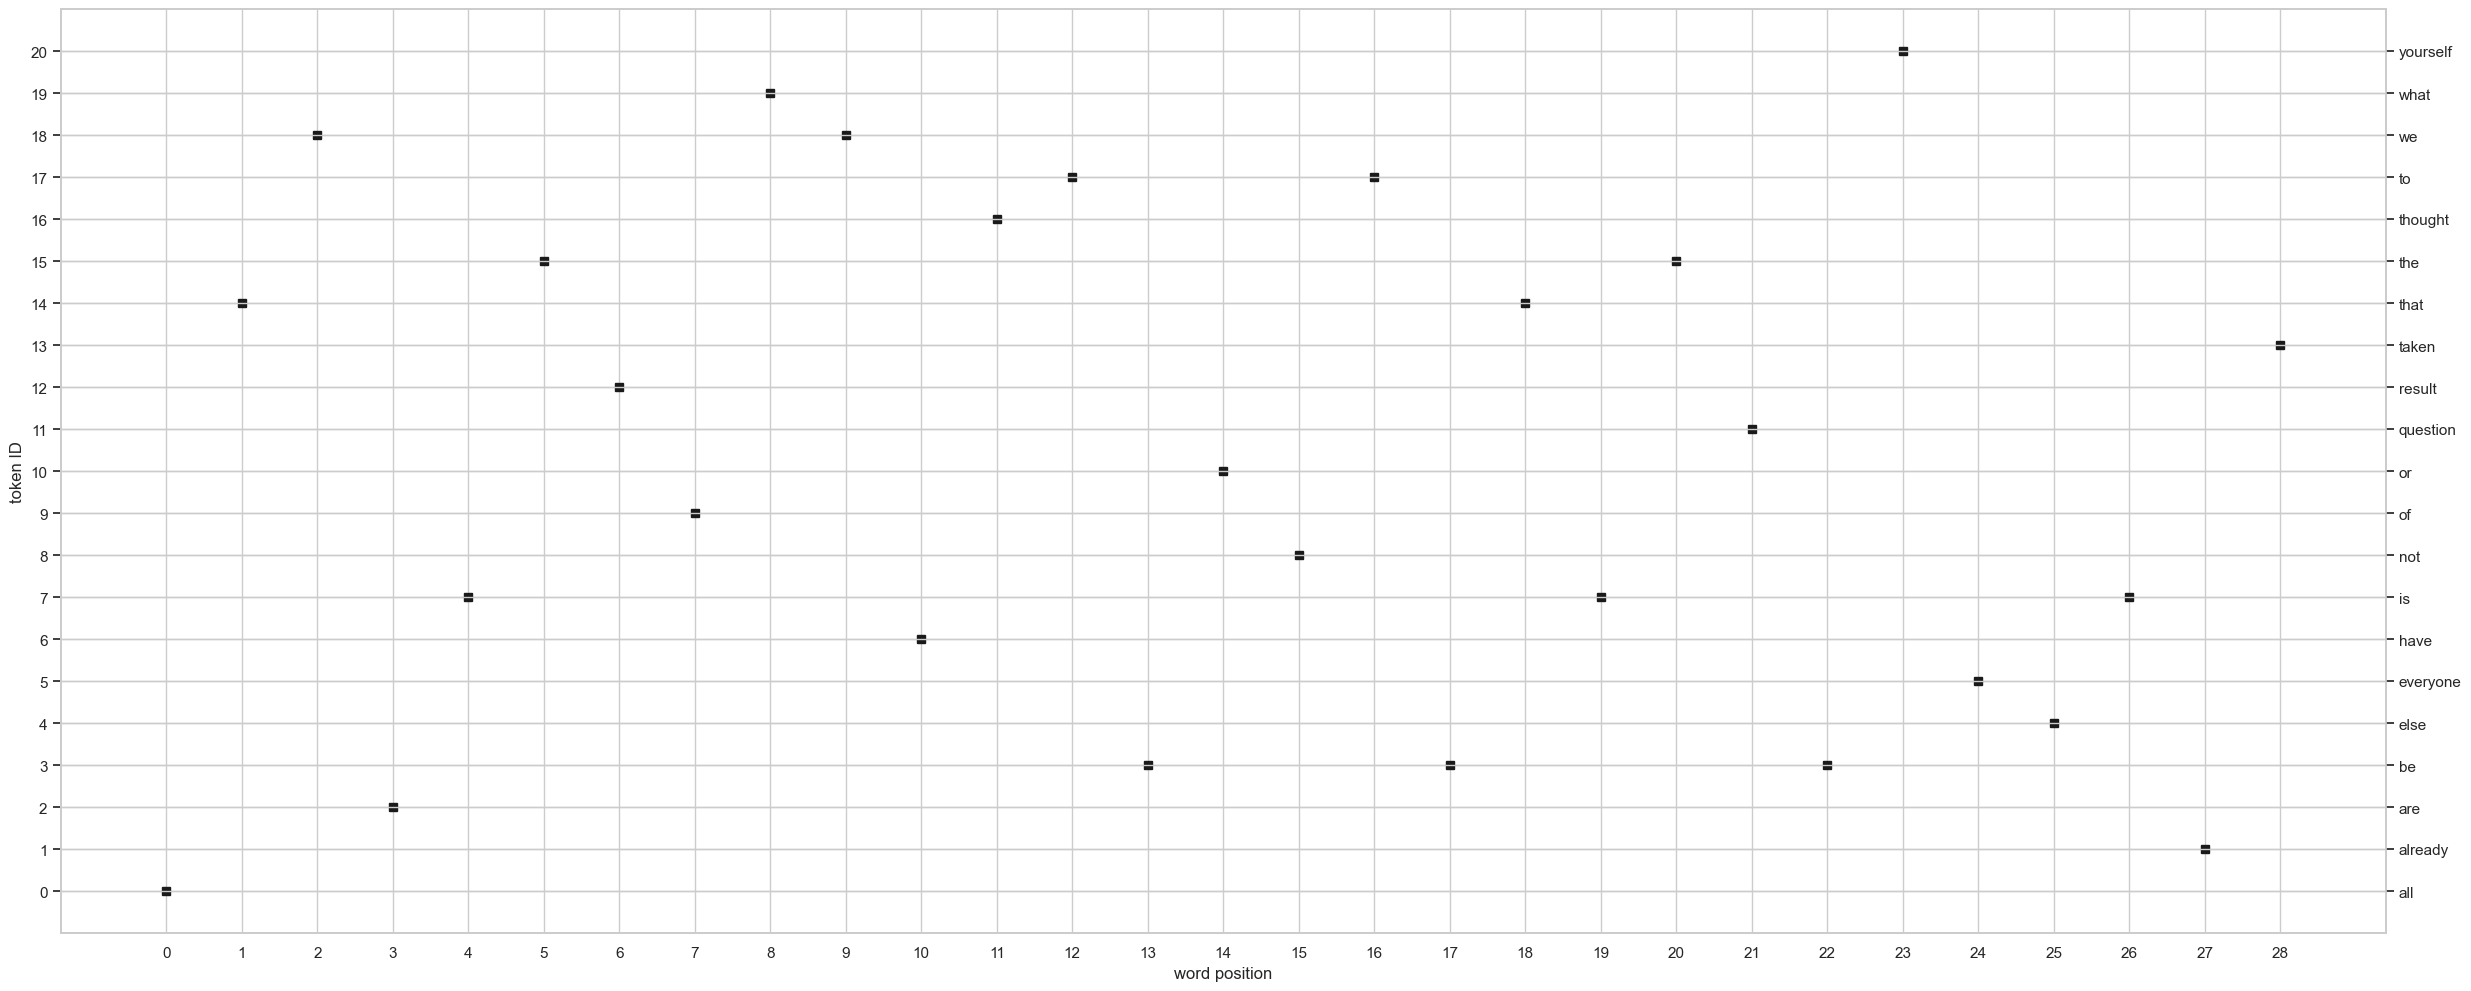

In [15]:
all_text = " ".join(sentences)
print(f"Text: {all_text}")

tokens = encoder(all_text)
word_pos = [i for i, _ in enumerate(all_text.split())]

fig, ax = plt.subplots(figsize=(30, 12))
ax.plot(word_pos, tokens, "ks")
ax.set_xticks(range(0, len(word_pos)))
ax.set_yticks(range(0, len(vocab)))
ax.set_ylabel("token ID")
ax.set_xlabel("word position");

ax_twin = ax.twinx()
ax_twin.plot(tokens, alpha=0)
ax_twin.set_yticks(range(0, len(vocab)), vocab);

## explore context surrounding target tokens

target token = "to"

In [16]:
target_token = "to"

pos = [i for i, x in enumerate(all_words) if x == target_token]
print(f"Index positions of the token `{target_token}`: {pos}")

print()
context = {}
for i in pos:
    context_words = all_words[i-1:i+2]
    context[" ".join(context_words)] = [word2idx[word] for word in context_words]

print(f"Context of `{target_token}`: {context}")

Index positions of the token `to`: [12, 16]

Context of `to`: {'thought to be': [16, 17, 3], 'not to be': [8, 17, 3]}


## OHE

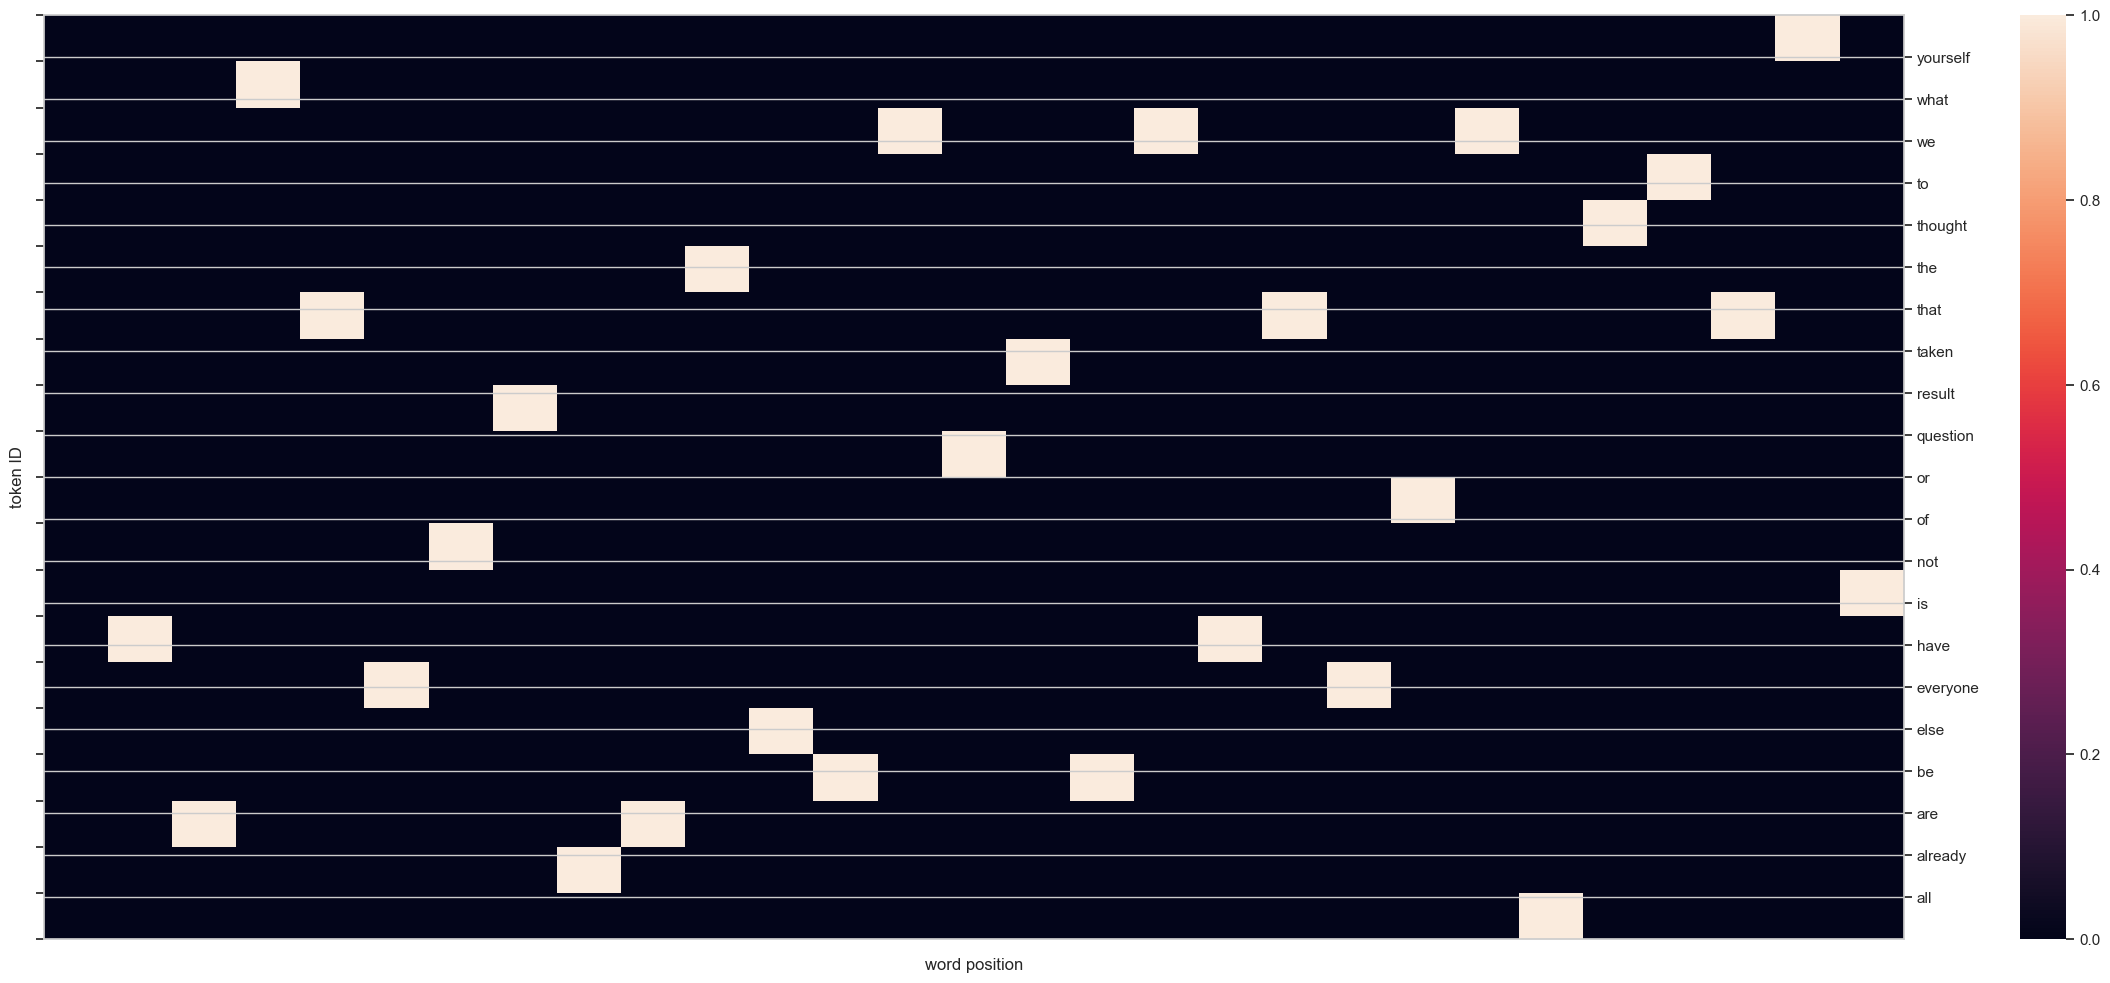

In [17]:
ohe = OneHotEncoder(drop="first", sparse_output=False)
ohe_mat = ohe.fit_transform(np.array(all_words).reshape(-1, 1))

fig, ax = plt.subplots(figsize=(30, 12))
sns.heatmap(ohe_mat.T, ax=ax)
ax.set_xticks(range(0, len(word_pos)))
ax.set_yticks(range(0, len(vocab)))
ax.set_ylabel("token ID")
ax.set_xlabel("word position")

ax_twin = ax.twinx()
ax_twin.plot(tokens, alpha=0)
ax_twin.set_yticks(range(0, len(vocab)), vocab);

# Tokenizing a full book (The Time Machine)

## prepare for tokenization

text cleaning

In [18]:
url = "https://www.gutenberg.org/files/35/35-0.txt"
# get raw text from internet
book = requests.get(url)
text = book.text
print(type(text))
print(len(text))

<class 'str'>
179799


In [247]:
# use this utility to preprocess the text (sentence); returns a list of words (tokens)

def preprocess(text, min_len=2):
    strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94','â\x80\x99','â\x80\x98','_']
    for s in strings2replace:
        regexp = re.compile(s)
        text = regexp.sub(" ", text)

    text = re.sub(r'[^\x00-\x7F]+', ' ', text) # non ASCII characters
    text = re.sub(r'\d+','',text).lower() # digits
    
    words = re.split(fr'[{string.punctuation}\s]+',text)
    words = [item.strip() for item in words if item.strip()]
    words = [item for item in words if len(item) >= min_len]

    return words

In [20]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [21]:
strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94','â\x80\x99','â\x80\x98','_']

for s in strings2replace:
    regexp = re.compile(s)
    text = regexp.sub(" ", text)

text = re.sub(r'[^\x00-\x7F]+', ' ', text) # non ASCII characters
text = re.sub(r'\d+','',text).lower() # digits

# split into words that contain >1 character
words = re.split(fr'[{string.punctuation}\s]+',text)
words = [item.strip() for item in words if item.strip()]
words = [item for item in words if len(item)>1]

# create the vocab / lexicon
vocab = sorted(set(words))
nWords = len(words)
nLex = len(vocab)

print(type(text))
print(len(text))

<class 'str'>
179781


In [22]:
(text[:2000])

'*** start of the project gutenberg ebook  ***\n\n\n\n\nthe time machine\n\nan invention\n\nby h. g. wells\n\n\ncontents\n\n i introduction\n ii the machine\n iii the time traveller returns\n iv time travelling\n v in the golden age\n vi the sunset of mankind\n vii a sudden shock\n viii explanation\n ix the morlocks\n x when night came\n xi the palace of green porcelain\n xii in the darkness\n xiii the trap of the white sphinx\n xiv the further vision\n xv the time traveller s return\n xvi after the story\n epilogue\n\n\n\n\n i.\n introduction\n\n\nthe time traveller (for so it will be convenient to speak of him)\nwas expounding a recondite matter to us. his grey eyes shone and\ntwinkled, and his usually pale face was flushed and animated. the\nfire burnt brightly, and the soft radiance of the incandescent\nlights in the lilies of silver caught the bubbles that flashed and\npassed in our glasses. our chairs, being his patents, embraced and\ncaressed us rather than submitted to be sat u

## tokenize

In [23]:
def encoder(words, encoder_dict):    
    return [encoder_dict[word.lower()] for word in words]

def decoder(idxs, decoder_dict):
    return [decoder_dict[idx] for idx in idxs]

idx2word = {i: word for i, word in enumerate(vocab)}
word2idx = {word: i for i, word in enumerate(vocab)}

print(encoder(["the", "time", "machine"], word2idx))
print(decoder([1, 3, 10], idx2word))

decoder(encoder(["the", "time", "machine"], word2idx), idx2word)

[4042, 4109, 2416]
['abandoned', 'abnormally', 'absent']


['the', 'time', 'machine']

### choose a sequence of tokens from a random starting point

In [24]:
start_idx = np.random.choice(len(words))
idxs = np.arange(start_idx, start_idx+10)
word_seq = [words[idx] for idx in idxs]

token_seq = encoder(word_seq, word2idx) #token IDs (integers)

print(f"Word indices: {idxs}")
print(f"Words: {word_seq}")
print(f"Token IDs: {token_seq}")
print(f"\n\nDecoded words:")
print(decoder(token_seq, idx2word))

Word indices: [27970 27971 27972 27973 27974 27975 27976 27977 27978 27979]
Words: ['of', 'thousand', 'years', 'or', 'more', 'drawn', 'on', 'by', 'the', 'mystery']
Token IDs: [2731, 4079, 4572, 2764, 2569, 1140, 2740, 506, 4042, 2612]


Decoded words:
['of', 'thousand', 'years', 'or', 'more', 'drawn', 'on', 'by', 'the', 'mystery']


### choose random tokens

same as above, but with random tokens

In [25]:
random_idxs = np.random.choice(len(words), size=(10))
word_seq = [words[idx] for idx in random_idxs]

token_seq = encoder(word_seq, word2idx) #token IDs (integers)

print(f"Word indices: {idxs}")
print(f"Words: {word_seq}")
print(f"Token IDs: {token_seq}")
print(f"\n\nDecoded words:")
print(decoder(token_seq, idx2word))

Word indices: [27970 27971 27972 27973 27974 27975 27976 27977 27978 27979]
Words: ['look', 'thick', 'and', 'me', 'trailed', 'had', 'rich', 'deliquesced', 'full', 'refreshing']
Token IDs: [2386, 4059, 137, 2470, 4153, 1815, 3321, 966, 1645, 3224]


Decoded words:
['look', 'thick', 'and', 'me', 'trailed', 'had', 'rich', 'deliquesced', 'full', 'refreshing']


### using brownian noise

same as above, but with random numbers as 1 or -1

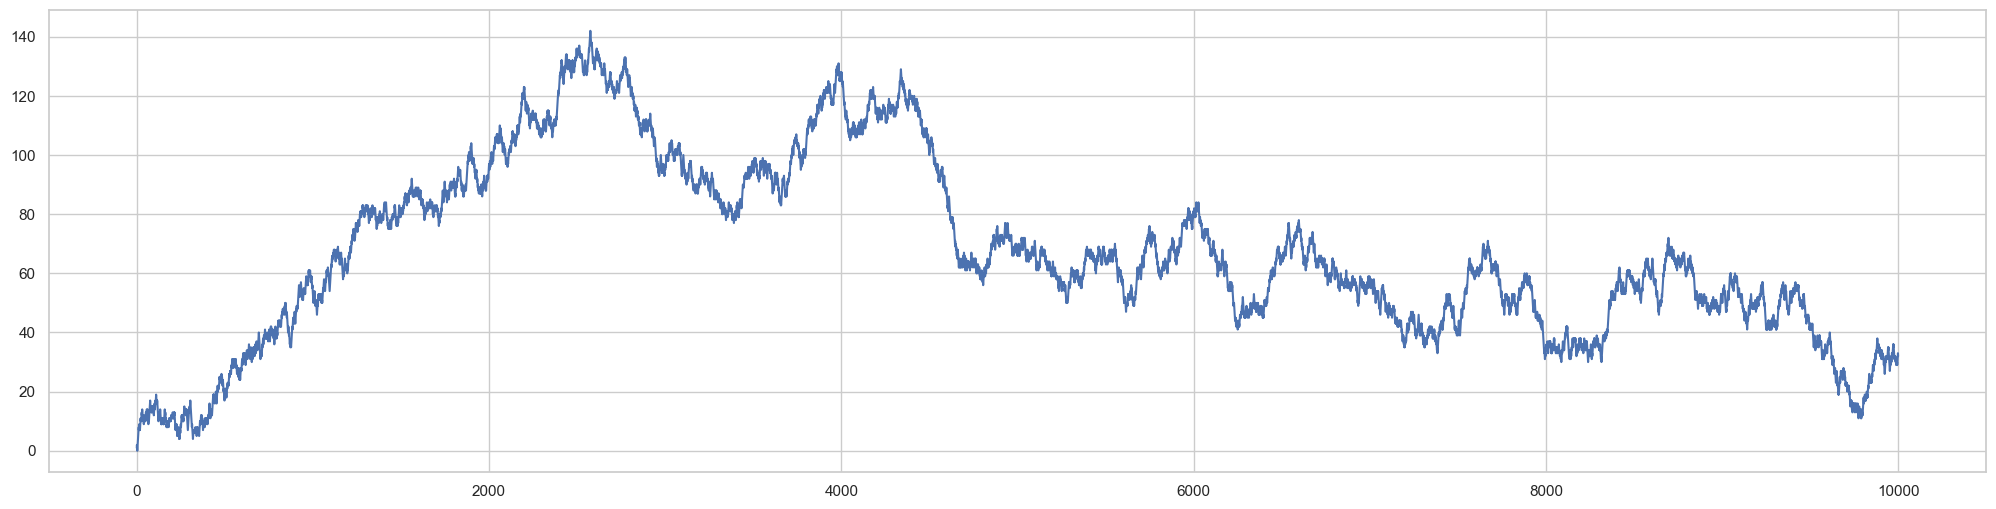

In [26]:
N = 10000
brownian_signal = np.random.choice([-1, 1], size=N)
brownian_random_walk = np.cumsum(brownian_signal)

plt.figure(figsize=(25, 6))
plt.plot(range(N), brownian_random_walk);

#### on our text 

In [27]:
brownian_signal = np.random.choice([-1, 1], size=10)

brownian_random_token = np.random.choice(len(vocab)) + brownian_signal
print(f"Brownian random token: {brownian_random_token}")

print(f"\n\nDecoded text:")
" ".join(decoder(brownian_random_token, idx2word))

Brownian random token: [1357 1357 1359 1357 1357 1359 1359 1359 1359 1357]


Decoded text:


'explore explore exploring explore explore exploring exploring exploring exploring explore'

In [28]:
len(words)

30699

## distribution of word lengths

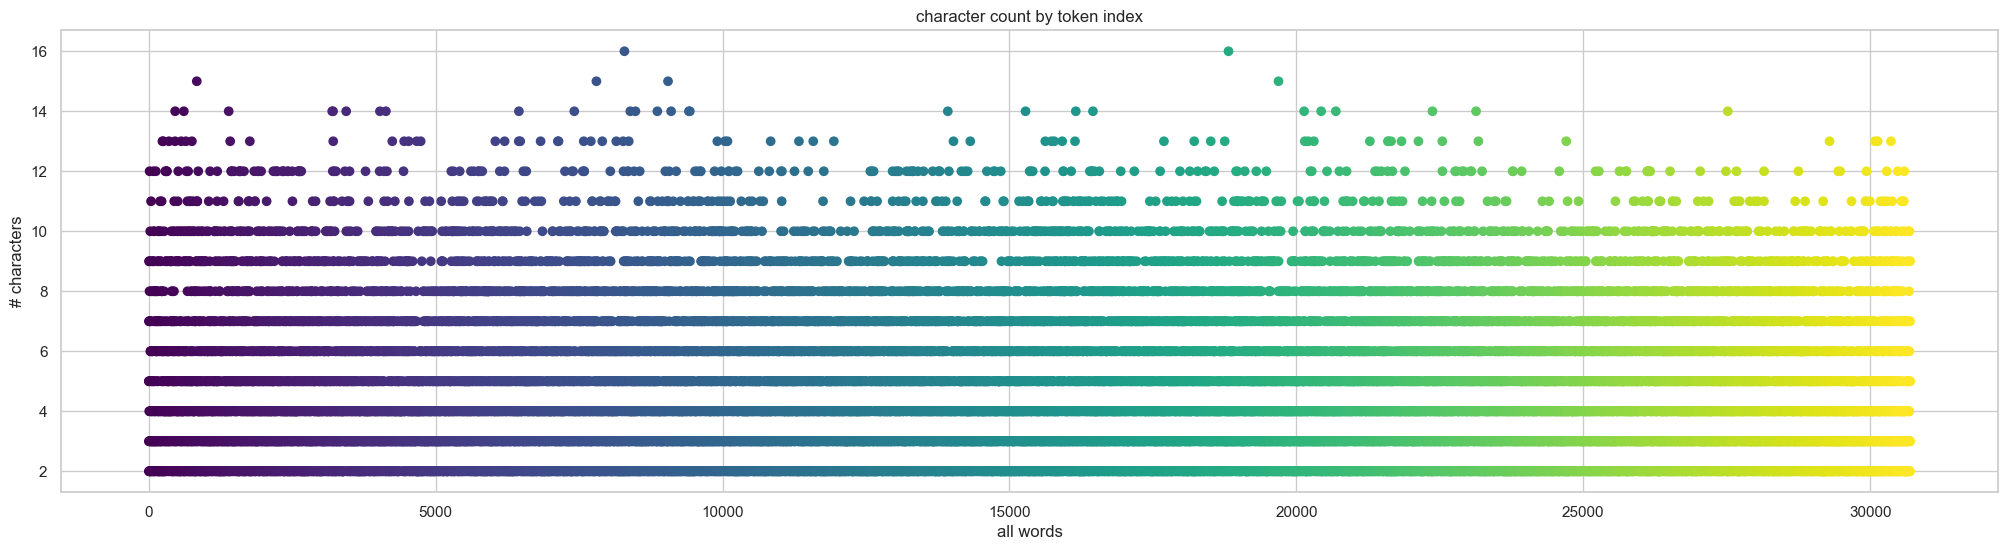

In [29]:
word_length_dist = {i: len(word) for i, word in enumerate(words)}

plt.figure(figsize=(25, 6))
plt.scatter(word_length_dist.keys(), word_length_dist.values(), c=range(len(words)), cmap="viridis")
plt.xlabel("all words")
plt.ylabel("# characters")
plt.title("character count by token index");

# density of words is higher for lower characters (words with few characters OR SIMPLY smaller words) than the higher characters
# longer word can appear earlier and later both, with equal probabilities

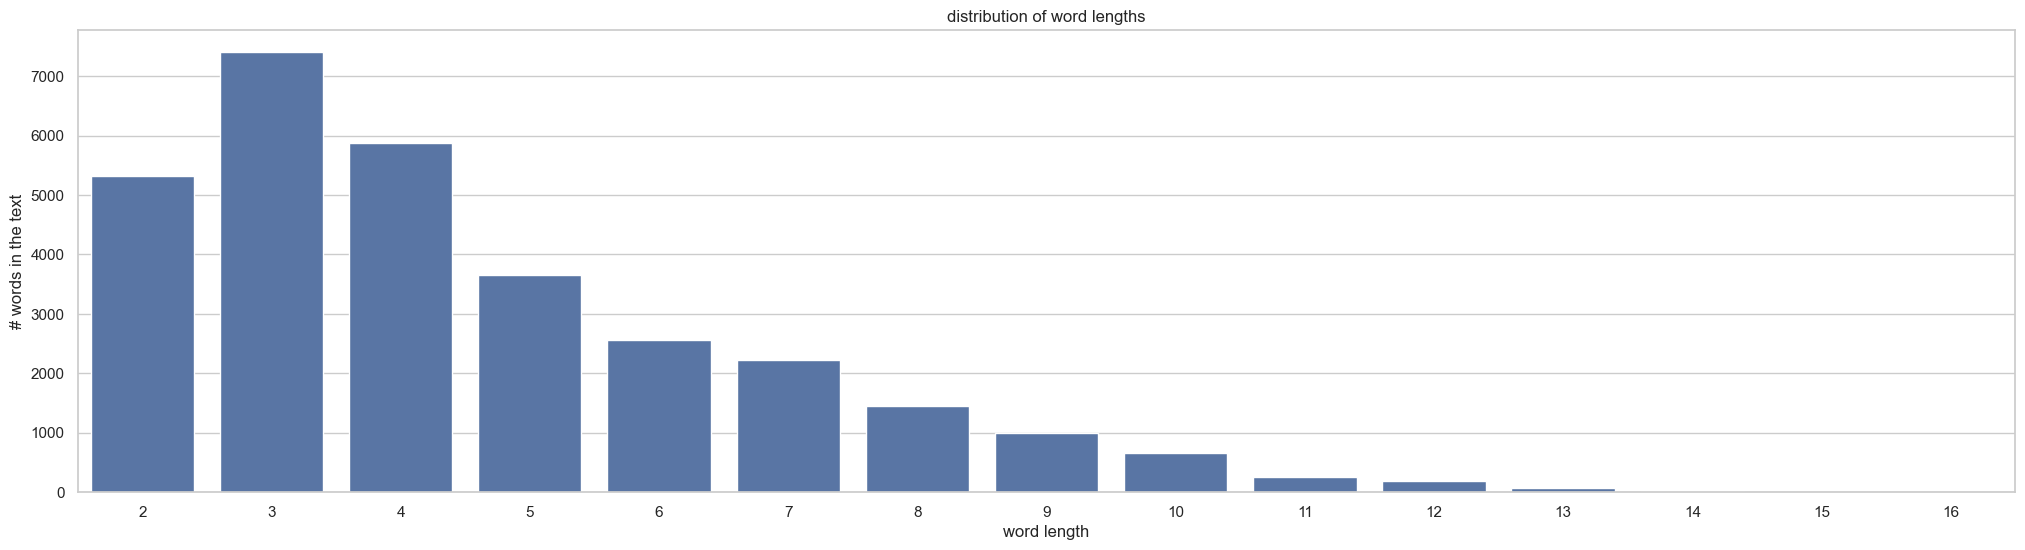

In [30]:
# frequency count: related to Zipf's law
# distribution is roughly like a negative exponential distribution: logarithmic relationship between the ordinal position of the word with the number of characters in that word

freq_count = {i: 0 for i in range(2, max(word_length_dist.values())+1)}

for word in words:
    freq_count[len(word)] += 1

plt.figure(figsize=(25, 6))
sns.barplot(x=freq_count.keys(), y=freq_count.values())
plt.title("distribution of word lengths")
plt.xlabel("word length")
plt.ylabel("# words in the text");

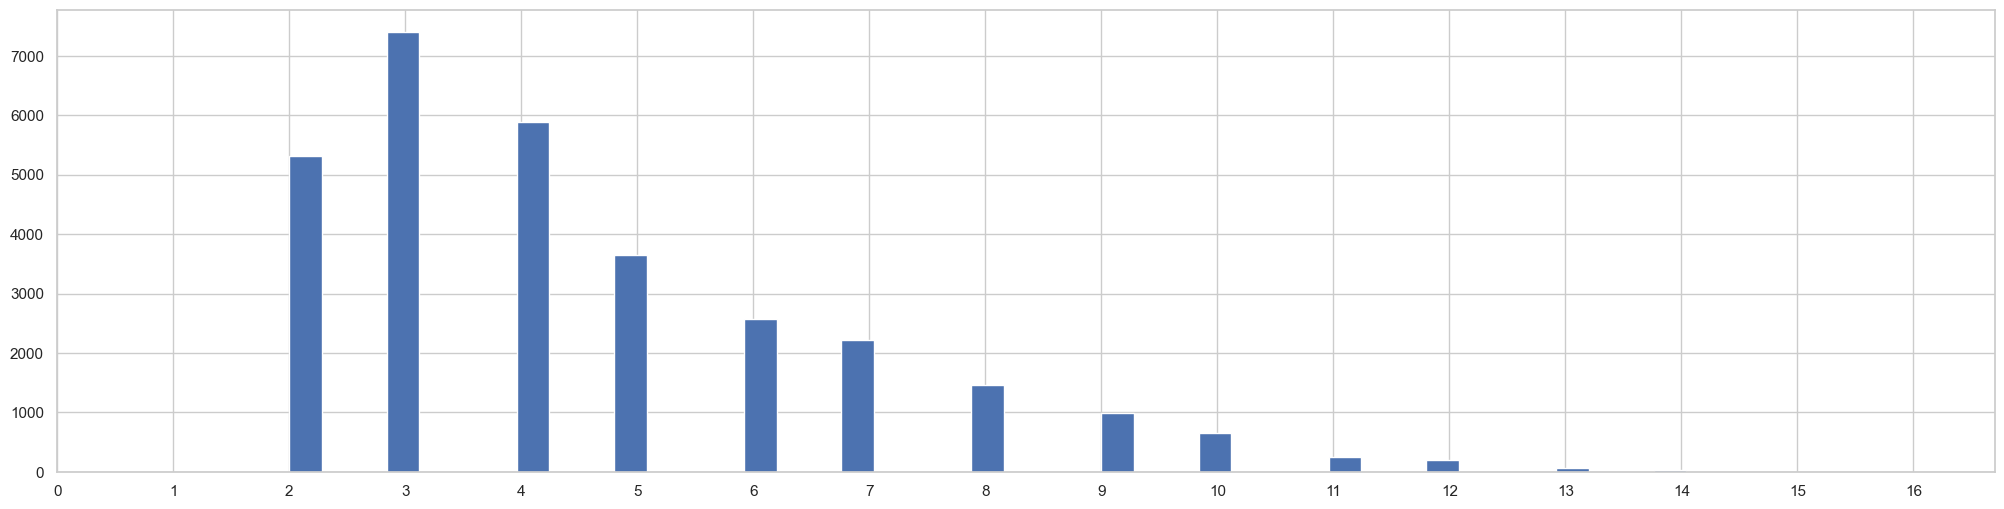

In [31]:
# same as above (bar <-> hist)
plt.figure(figsize=(25, 6))
plt.hist(word_length_dist.values(), bins=50);
plt.xticks(range(0, max(word_length_dist.values())+1));

## encoding a novel sentence

In [32]:
sentence = 'The space aliens came to Earth to steal watermelons and staplers.'

words_new = preprocess(sentence)
encoder(words_new, word2idx)

KeyError: 'aliens'

## updating the encoder and decoder
only encoder needs to be updated

In [33]:
word2idx["<|unk|>"] = len(word2idx)
idx2word[len(idx2word)] = "<|unk|>"

print(f"# Unique tokens: {len(word2idx.keys())} (after including |<unk>|)") # len(vocab) = 4589 (one less)
print()

def encoder(words, encoder_dict):    # returns token idxs
    return [encoder_dict[word] if word in encoder_dict.keys() else encoder_dict["<|unk|>"] for word in words]

def decoder(idxs, decoder_dict):
    return " ".join([decoder_dict[idx] for idx in idxs])

print(sentence)
print(encoder(words_new, word2idx))
print()
print(decoder(encoder(words_new, word2idx), idx2word)) # lossy encoding/ decoding scheme

# Unique tokens: 4590 (after including |<unk>|)

The space aliens came to Earth to steal watermelons and staplers.
[4042, 3734, 4589, 519, 4119, 1191, 4119, 4589, 4589, 137, 4589]

the space <|unk|> came to earth to <|unk|> <|unk|> and <|unk|>


In [34]:
idx2word[len(word2idx)]

KeyError: 4590

# Encoding with subwords

## Byte-pair encoding

### first iteration

In [35]:
text = list('like liker love lovely hug hugs hugging hearts')
print(f"Original text: {text}")
chars = sorted(set([char for char in text]))

# initialize a dictionary
vocab = {char: i for i, char in enumerate(chars)}
print(f"Vocab: {vocab}")
print()

token_seq = [char for char in text]
print(f"Token sequence: {token_seq}")
token_idxs = [vocab[char] for char in token_seq]
print(f"Token idxs: {token_idxs}")
print()

# form token pairs and find the most frequent token pair
token_pairs = ["".join(text[i:i+2]) for i in range(len(text)-1)]
token_pair_freq = {token_pair: token_pairs.count(token_pair) for token_pair in token_pairs}
most_common_pairs = [k for k, v in token_pair_freq.items() if v == max(token_pair_freq.values())]

# update the vocab
vocab[most_common_pairs[0]] = len(vocab)
print(f"Vocab: {vocab}")

print("\n"*5)

# replacing the text and generating new token list

# updating the token sequence
token_seq = []

i = 0
while i < len(text):
    token = "".join(text[i:i+2])
    if token in vocab.keys():
        token_seq.append(token)
        i += 2
    else:
        token_seq.append(text[i])
        i += 1

print(f"Token sequence (new): {token_seq}")

token_idxs = [vocab[char] for char in token_seq]
print(f"Token idxs (new): {token_idxs}")
print()

Original text: ['l', 'i', 'k', 'e', ' ', 'l', 'i', 'k', 'e', 'r', ' ', 'l', 'o', 'v', 'e', ' ', 'l', 'o', 'v', 'e', 'l', 'y', ' ', 'h', 'u', 'g', ' ', 'h', 'u', 'g', 's', ' ', 'h', 'u', 'g', 'g', 'i', 'n', 'g', ' ', 'h', 'e', 'a', 'r', 't', 's']
Vocab: {' ': 0, 'a': 1, 'e': 2, 'g': 3, 'h': 4, 'i': 5, 'k': 6, 'l': 7, 'n': 8, 'o': 9, 'r': 10, 's': 11, 't': 12, 'u': 13, 'v': 14, 'y': 15}

Token sequence: ['l', 'i', 'k', 'e', ' ', 'l', 'i', 'k', 'e', 'r', ' ', 'l', 'o', 'v', 'e', ' ', 'l', 'o', 'v', 'e', 'l', 'y', ' ', 'h', 'u', 'g', ' ', 'h', 'u', 'g', 's', ' ', 'h', 'u', 'g', 'g', 'i', 'n', 'g', ' ', 'h', 'e', 'a', 'r', 't', 's']
Token idxs: [7, 5, 6, 2, 0, 7, 5, 6, 2, 10, 0, 7, 9, 14, 2, 0, 7, 9, 14, 2, 7, 15, 0, 4, 13, 3, 0, 4, 13, 3, 11, 0, 4, 13, 3, 3, 5, 8, 3, 0, 4, 2, 1, 10, 12, 11]

Vocab: {' ': 0, 'a': 1, 'e': 2, 'g': 3, 'h': 4, 'i': 5, 'k': 6, 'l': 7, 'n': 8, 'o': 9, 'r': 10, 's': 11, 't': 12, 'u': 13, 'v': 14, 'y': 15, ' h': 16}






Token sequence (new): ['l', 'i', 'k', 'e', 

### second iteration

In [36]:
text = token_seq

# form token pairs and find the most frequent token pair
token_pairs = ["".join(text[i:i+2]) for i in range(len(text)-1)]
token_pair_freq = {token_pair: token_pairs.count(token_pair) for token_pair in token_pairs}
most_common_pairs = [k for k, v in token_pair_freq.items() if v == max(token_pair_freq.values())]

# update the vocab
vocab[most_common_pairs[0]] = len(vocab)
print(f"Vocab: {vocab}")

print("\n"*5)

# replacing the text and generating new token list

# updating the token sequence
token_seq = []

i = 0
while i < len(text):
    token = "".join(text[i:i+2])
    if token in vocab.keys():
        token_seq.append(token)
        i += 2
    else:
        token_seq.append(text[i])
        i += 1

print(f"Token sequence (new): {token_seq}")

token_idxs = [vocab[char] for char in token_seq]
print(f"Token idxs (new): {token_idxs}")
print()

Vocab: {' ': 0, 'a': 1, 'e': 2, 'g': 3, 'h': 4, 'i': 5, 'k': 6, 'l': 7, 'n': 8, 'o': 9, 'r': 10, 's': 11, 't': 12, 'u': 13, 'v': 14, 'y': 15, ' h': 16, ' l': 17}






Token sequence (new): ['l', 'i', 'k', 'e', ' l', 'i', 'k', 'e', 'r', ' l', 'o', 'v', 'e', ' l', 'o', 'v', 'e', 'l', 'y', ' h', 'u', 'g', ' h', 'u', 'g', 's', ' h', 'u', 'g', 'g', 'i', 'n', 'g', ' h', 'e', 'a', 'r', 't', 's']
Token idxs (new): [7, 5, 6, 2, 17, 5, 6, 2, 10, 17, 9, 14, 2, 17, 9, 14, 2, 7, 15, 16, 13, 3, 16, 13, 3, 11, 16, 13, 3, 3, 5, 8, 3, 16, 2, 1, 10, 12, 11]



In [37]:
text

['l',
 'i',
 'k',
 'e',
 ' ',
 'l',
 'i',
 'k',
 'e',
 'r',
 ' ',
 'l',
 'o',
 'v',
 'e',
 ' ',
 'l',
 'o',
 'v',
 'e',
 'l',
 'y',
 ' h',
 'u',
 'g',
 ' h',
 'u',
 'g',
 's',
 ' h',
 'u',
 'g',
 'g',
 'i',
 'n',
 'g',
 ' h',
 'e',
 'a',
 'r',
 't',
 's']

### final code - using functions

In [38]:
def get_token_pair_freq(text2pair):
    token_pairs = ["".join(text2pair[i:i+2]) for i in range(len(text2pair)-1)]
    return {token_pair : token_pairs.count(token_pair) for token_pair in token_pairs}

text = list('like liker love lovely hug hugs hugging hearts')
print(get_token_pair_freq(text))

{'li': 2, 'ik': 2, 'ke': 2, 'e ': 2, ' l': 3, 'er': 1, 'r ': 1, 'lo': 2, 'ov': 2, 've': 2, 'el': 1, 'ly': 1, 'y ': 1, ' h': 4, 'hu': 3, 'ug': 3, 'g ': 2, 'gs': 1, 's ': 1, 'gg': 1, 'gi': 1, 'in': 1, 'ng': 1, 'he': 1, 'ea': 1, 'ar': 1, 'rt': 1, 'ts': 1}


In [39]:
text = list('like liker love lovely hug hugs hugging hearts')
vocab = {char : i for i, char in enumerate(sorted(set(text)))}

def update_vocab(token_pair_freq, vocab):
    idx = np.argmax(list(token_pair_freq.values()))
    new_token = list(token_pair_freq.keys())[idx]
    vocab[new_token] = max(vocab.values())+1
    return vocab, new_token

print(update_vocab(get_token_pair_freq(text), vocab))

({' ': 0, 'a': 1, 'e': 2, 'g': 3, 'h': 4, 'i': 5, 'k': 6, 'l': 7, 'n': 8, 'o': 9, 'r': 10, 's': 11, 't': 12, 'u': 13, 'v': 14, 'y': 15, ' h': 16}, ' h')


In [40]:
def generate_new_token_seq(previous_text, new_token):
    new_text = []
    i = 0
    while i < len(previous_text):
        if "".join(previous_text[i:i+2]) == new_token:
            new_text.append(new_token)
            i += 2
        else:
            new_text.append(previous_text[i])
            i += 1    
    return new_text

_, new_token = update_vocab(get_token_pair_freq(text), vocab)
print(generate_new_token_seq(text, new_token))

['l', 'i', 'k', 'e', ' ', 'l', 'i', 'k', 'e', 'r', ' ', 'l', 'o', 'v', 'e', ' ', 'l', 'o', 'v', 'e', 'l', 'y', ' h', 'u', 'g', ' h', 'u', 'g', 's', ' h', 'u', 'g', 'g', 'i', 'n', 'g', ' h', 'e', 'a', 'r', 't', 's']


### writing all together

In [41]:
def get_token_pair_freq(text2pair):
    token_pairs = ["".join(text2pair[i:i+2]) for i in range(len(text2pair)-1)]
    return {token_pair : token_pairs.count(token_pair) for token_pair in token_pairs}

def update_vocab(token_pair_freq, vocab):
    idx = np.argmax(list(token_pair_freq.values()))
    new_token = list(token_pair_freq.keys())[idx]
    vocab[new_token] = max(vocab.values())+1
    return vocab, new_token

def generate_new_token_seq(previous_text, new_token):
    new_text = []
    i = 0
    while i < len(previous_text):
        if "".join(previous_text[i:i+2]) == new_token:
            new_text.append(new_token)
            i += 2
        else:
            new_text.append(previous_text[i])
            i += 1    
    return new_text

text = list('like liker love lovely hug hugs hugging hearts')
vocab = {char : i for i, char in enumerate(sorted(set(text)))}
print(f"Vocab has {len(vocab)} pairs")

# iteration 1:
token_pair_freq = get_token_pair_freq(text)
vocab, new_token = update_vocab(token_pair_freq, vocab)
new_text = generate_new_token_seq(text, new_token)
print(f"Vocab has {len(vocab)} pairs")

Vocab has 16 pairs
Vocab has 17 pairs


### BPE in a loop until the vocab contains 25 tokens

In [42]:
text = list('like liker love lovely hug hugs hugging hearts')
vocab = {char : i for i, char in enumerate(sorted(set(text)))}
print(f"Vocab has {len(vocab)} pairs")

updated_text = text.copy()

while len(vocab.keys()) < 25:    
    token_pair_freq = get_token_pair_freq(updated_text)
    vocab, new_token = update_vocab(token_pair_freq, vocab)
    updated_text = generate_new_token_seq(updated_text, new_token)
    print(f"Vocab has {len(vocab)} pairs")

Vocab has 16 pairs
Vocab has 17 pairs
Vocab has 18 pairs
Vocab has 19 pairs
Vocab has 20 pairs
Vocab has 21 pairs
Vocab has 22 pairs
Vocab has 23 pairs
Vocab has 24 pairs
Vocab has 25 pairs


In [43]:
vocab

{' ': 0,
 'a': 1,
 'e': 2,
 'g': 3,
 'h': 4,
 'i': 5,
 'k': 6,
 'l': 7,
 'n': 8,
 'o': 9,
 'r': 10,
 's': 11,
 't': 12,
 'u': 13,
 'v': 14,
 'y': 15,
 ' h': 16,
 ' l': 17,
 ' hu': 18,
 ' hug': 19,
 'ik': 20,
 'ike': 21,
 ' lo': 22,
 ' lov': 23,
 ' love': 24}

# Tiktoken

## introduction with GPT tokenizer

In [44]:
tokenizer = tiktoken.get_encoding("cl100k_base")
print(dir(tokenizer))

['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setstate__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_core_bpe', '_encode_bytes', '_encode_only_native_bpe', '_encode_single_piece', '_mergeable_ranks', '_pat_str', '_special_token_values', '_special_tokens', 'decode', 'decode_batch', 'decode_bytes', 'decode_bytes_batch', 'decode_single_token_bytes', 'decode_tokens_bytes', 'decode_with_offsets', 'encode', 'encode_batch', 'encode_ordinary', 'encode_ordinary_batch', 'encode_single_token', 'encode_to_numpy', 'encode_with_unstable', 'eot_token', 'is_special_token', 'max_token_value', 'n_vocab', 'name', 'special_tokens_set', 'token_byte_values']


In [45]:
tokenizer.n_vocab

100277

In [46]:
tokenizer.decode([tokenizer.eot_token])

'<|endoftext|>'

In [47]:
tokenizer.decode([100245])

'_RECEIVED'

In [48]:
tokenizer.encode("dhrumy")

[67, 4171, 372, 88]

In [49]:
tokenizer.decode([67, 4171, 372, 88])

'dhrumy'

### distribution of token lengths

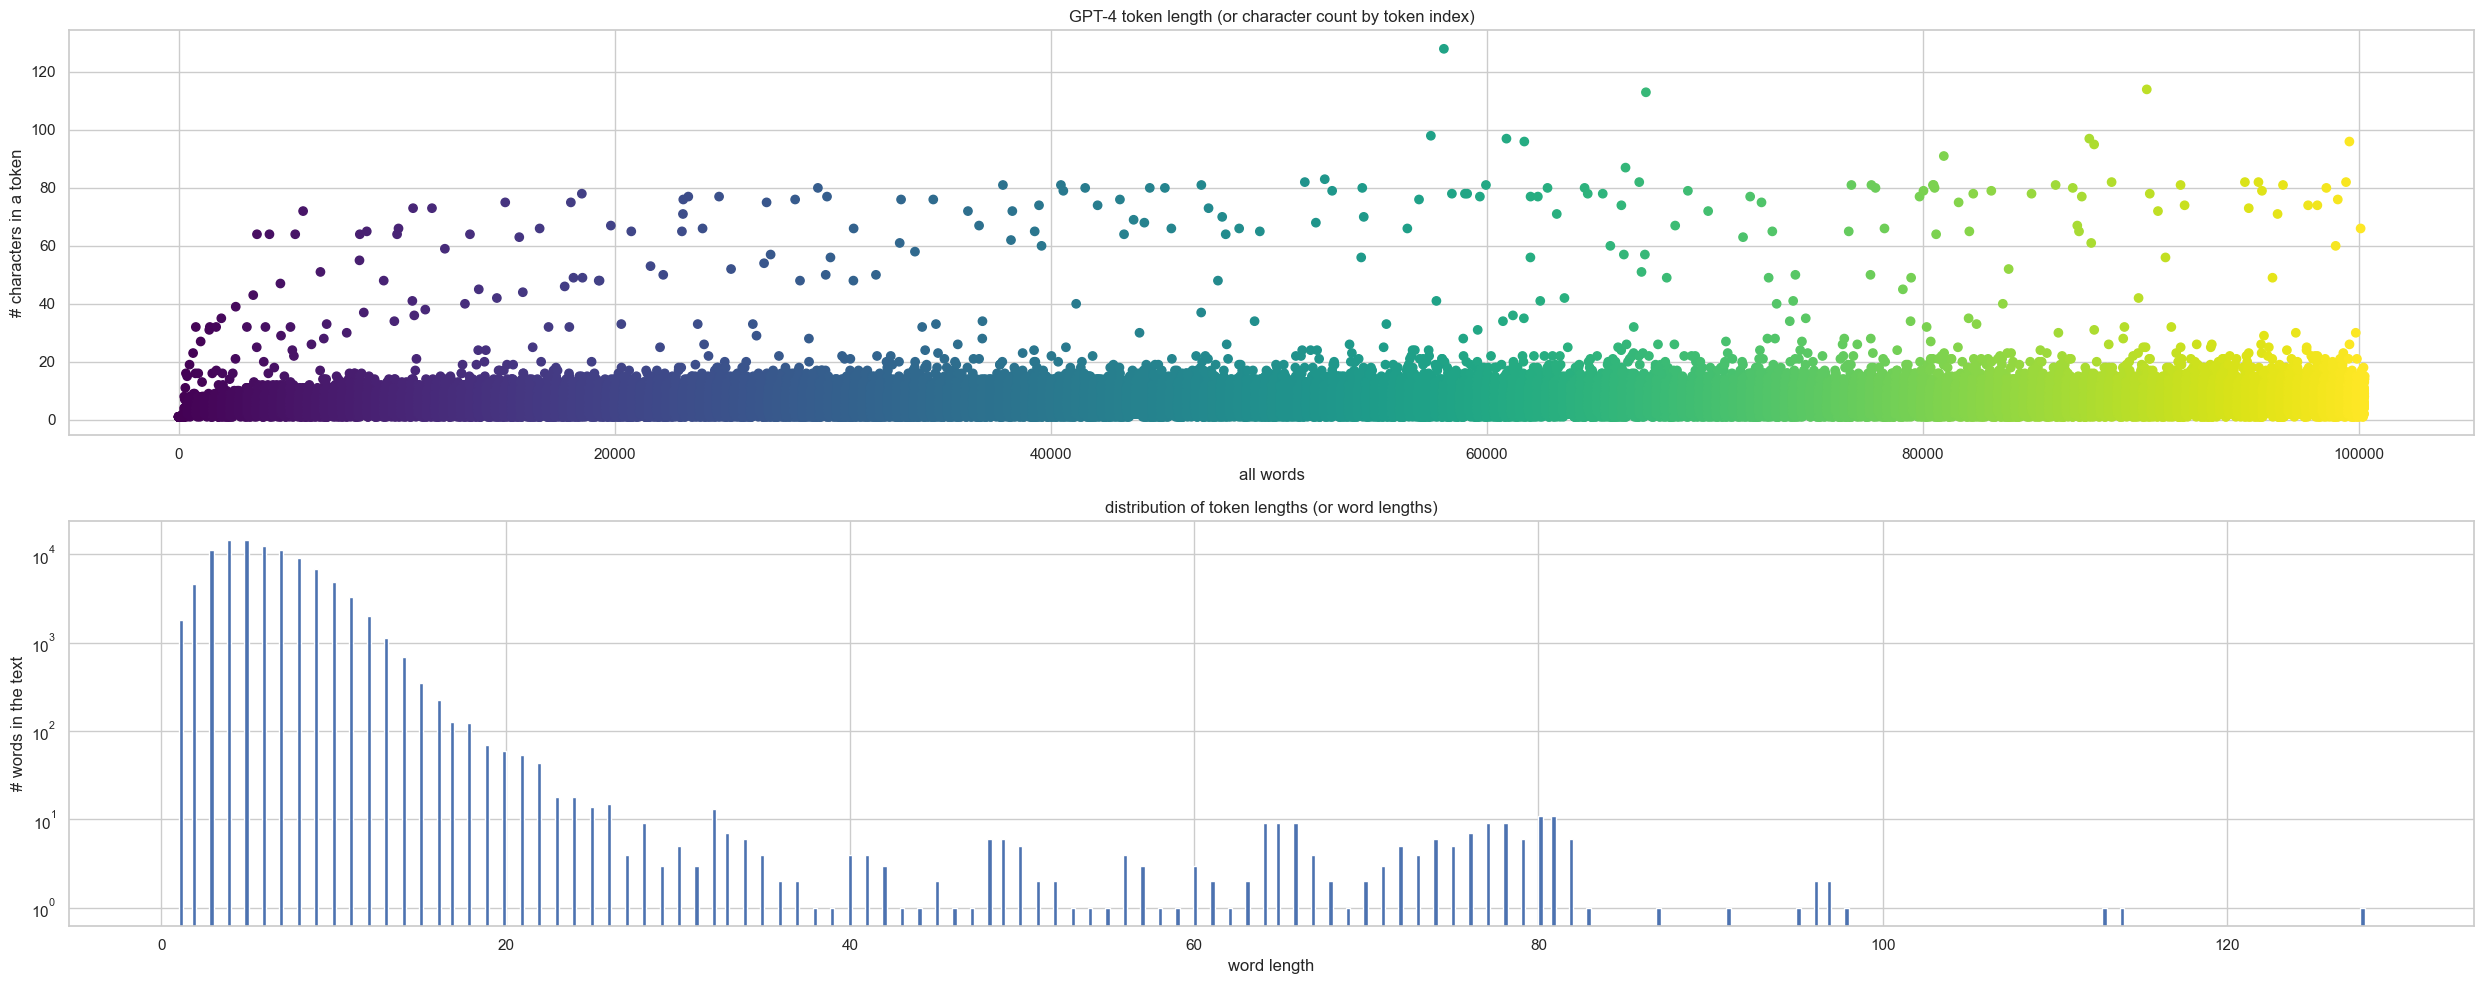

In [50]:

token_lengths = {}
for idx in range(tokenizer.n_vocab):
    try:
        token_lengths[idx] = len(tokenizer.decode([idx]))
    except:
        token_lengths[idx] = np.nan

fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(25, 10))
ax[0].scatter(token_lengths.keys(), token_lengths.values(), c=range(tokenizer.n_vocab), cmap="viridis")
ax[0].set_xlabel("all words")
ax[0].set_ylabel("# characters in a token")
ax[0].set_title("GPT-4 token length (or character count by token index)");

ax[1].hist(token_lengths.values(), bins=500);
ax[1].set_title("distribution of token lengths (or word lengths)")
ax[1].set_xlabel("word length")
ax[1].set_ylabel("# words in the text")
ax[1].set_yscale("log")

plt.tight_layout()

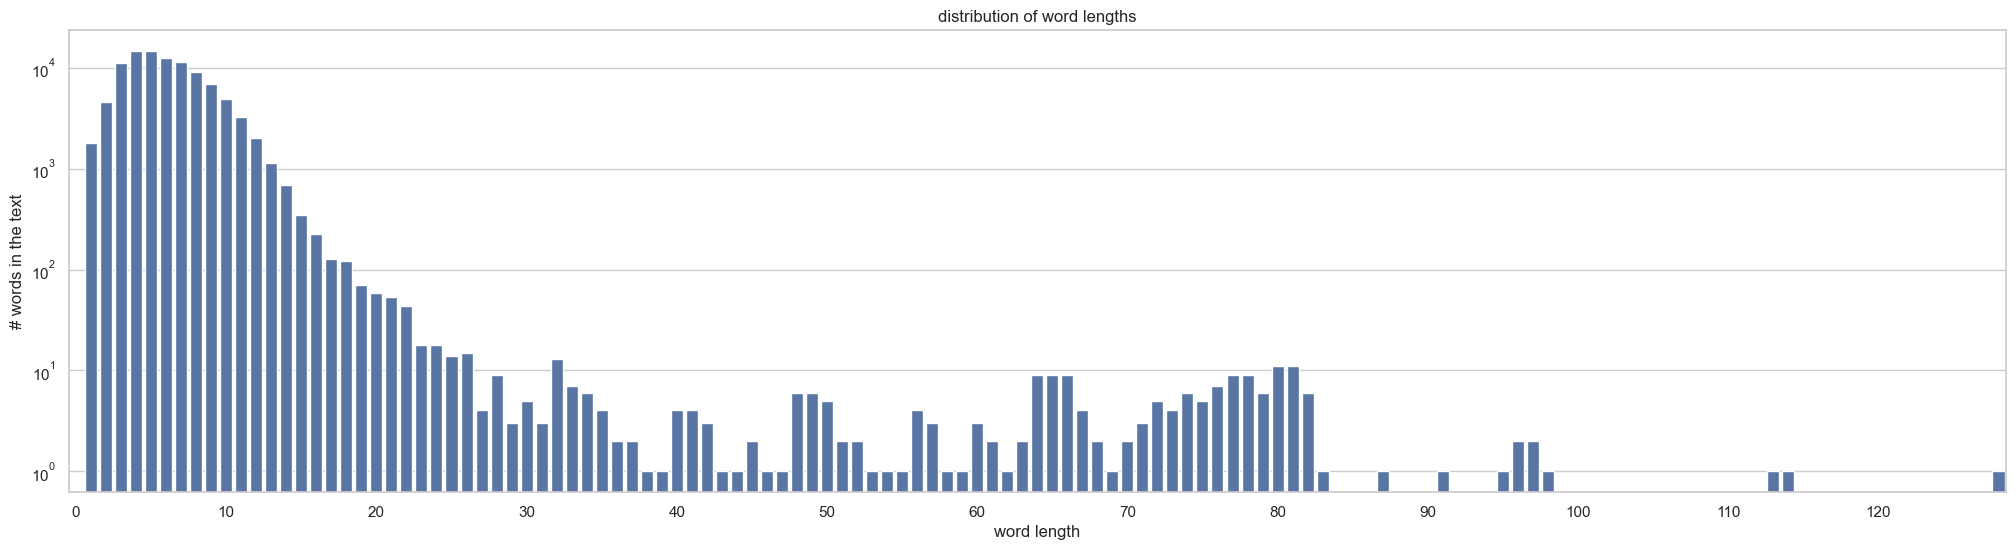

In [51]:
freq_count = {i: 0 for i in range(0, max(token_lengths.values())+1)}

for idx in range(tokenizer.n_vocab):
    try:
        freq_count[len(tokenizer.decode([idx]))] += 1
    except:
        pass

plt.figure(figsize=(25, 6))
sns.barplot(x=freq_count.keys(), y=freq_count.values())
plt.title("distribution of word lengths")
plt.xlabel("word length")
plt.ylabel("# words in the text")
plt.yscale("log")
plt.xticks(range(0, max(token_lengths.values())+1, 10));

In [52]:
# longer words:

[tokenizer.decode([k]) for k, v in token_lengths.items() if v > 100]

['                                                                                                                                ',
 ' ----------------------------------------------------------------------------------------------------------------',
 '//----------------------------------------------------------------------------------------------------------------']

In [54]:
# tokens differ if they start with space
print(tokenizer.encode("dhrumpy"))
print(tokenizer.encode(" dhrumpy"))
print()
print(tokenizer.encode("Michael"))
print(tokenizer.encode(" Michael"))

[67, 4171, 6895]
[294, 4171, 6895]

[26597]
[8096]


In [55]:
print(tokenizer.decode([67]))
print(tokenizer.decode([4171]))
print(tokenizer.decode([6895]))

d
hr
umpy


In [56]:
# words starting with space:
tokens_starting_with_space = []
for idx in range(tokenizer.n_vocab):
    try:
        token = tokenizer.decode([idx])
        if token[0] == " ":
            tokens_starting_with_space.append(token)
    except:
        pass
len(tokens_starting_with_space)

44610

## encoding the time machine book

In [57]:
url = "https://www.gutenberg.org/files/35/35-0.txt"
# get raw text from internet
book = requests.get(url)
text = book.text

words = text.split()
len(words)

32472

In [58]:
# choose a random word and encode it

random_word = np.random.choice(words)
print(f"`{random_word}` is encoded as {tokenizer.encode(random_word)}")

`the` is encoded as [1820]


In [59]:
# number of tokens in any randomly selected 10 tokens

random_words = np.random.choice(words, size=10)
[{str(random_word): tokenizer.encode(random_word)} for random_word in random_words]

[{'to': [998]},
 {'illuminated.': [484, 10318, 660, 13]},
 {'flowers.': [89770, 13]},
 {'and': [438]},
 {'in': [258]},
 {'did': [23770]},
 {'appearance': [97755]},
 {'the': [1820]},
 {'and': [438]},
 {'of': [1073]}]

In [60]:
# encoding with incorrect spellings

words = ["book", "Book", "bOok", "b0ok", "b00k", "books", "BOOK", "BOOKS"]
[{str(word): tokenizer.encode(word)} for word in words]

[{'book': [2239]},
 {'Book': [7280]},
 {'bOok': [65, 46, 564]},
 {'b0ok': [65, 15, 564]},
 {'b00k': [65, 410, 74]},
 {'books': [12383]},
 {'BOOK': [37725]},
 {'BOOKS': [37725, 50]}]

In [61]:
# encoding the entire book all at once

token_seq = tokenizer.encode(text)
len(token_seq)

42946

### Tokenizing the Time Machine book with tiktoken

The time machine book

In [62]:
text = requests.get("https://www.gutenberg.org/files/35/35-0.txt").text
text = preprocess(text)
tokens = [{str(word): tokenizer.encode(word)} for word in text]
len(tokens)

30699

#### check if longer words require more tokens to represent?

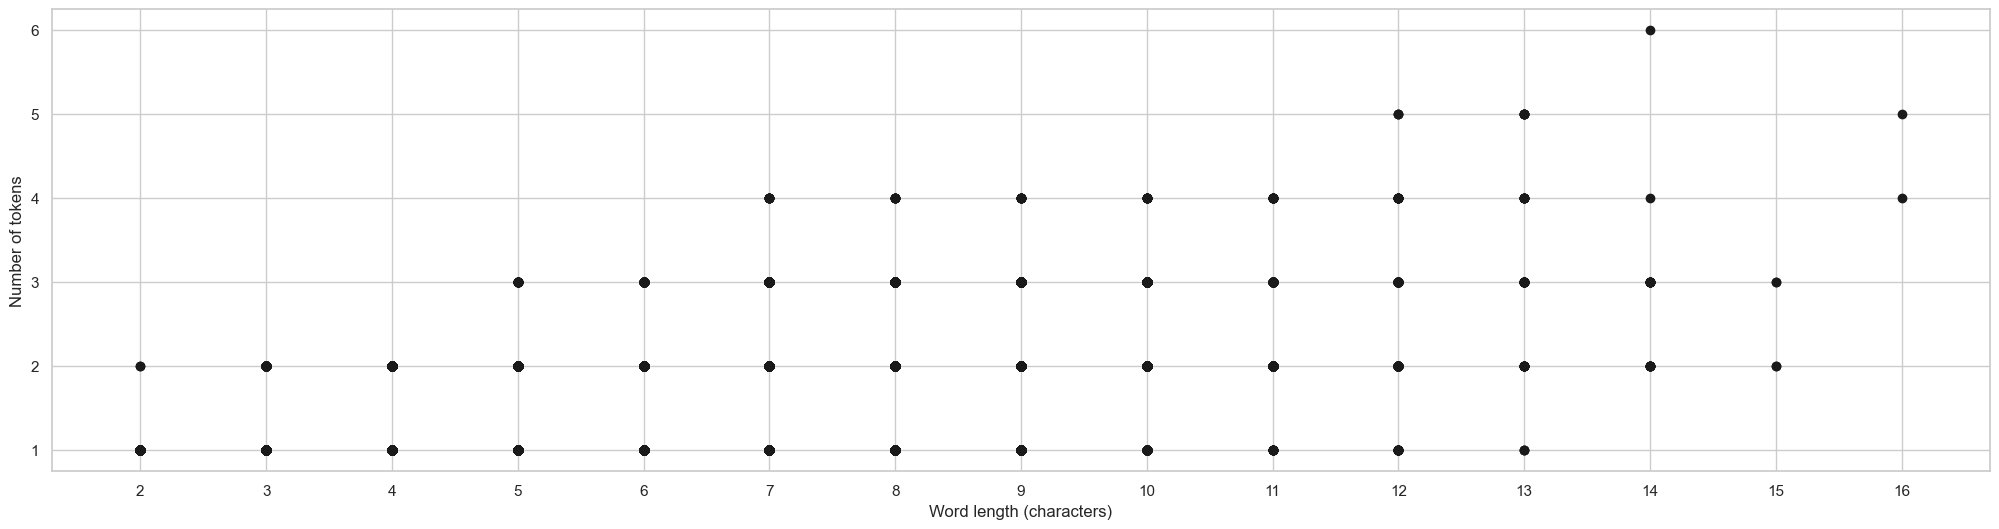

In [63]:
get_token_count = lambda word : len(tokenizer.encode(word))

token_counts = {}
for word in text:
    if len(word) not in token_counts.keys():
        token_counts[len(word)] = [get_token_count(word)]
    else:
        token_counts[len(word)].append(get_token_count(word))

plt.figure(figsize=(25, 6))
for length, counts in token_counts.items():
    lengths = [length]*len(counts)
    plt.scatter(lengths, counts, color="k")
plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens")
plt.xticks(sorted(token_counts.keys()));

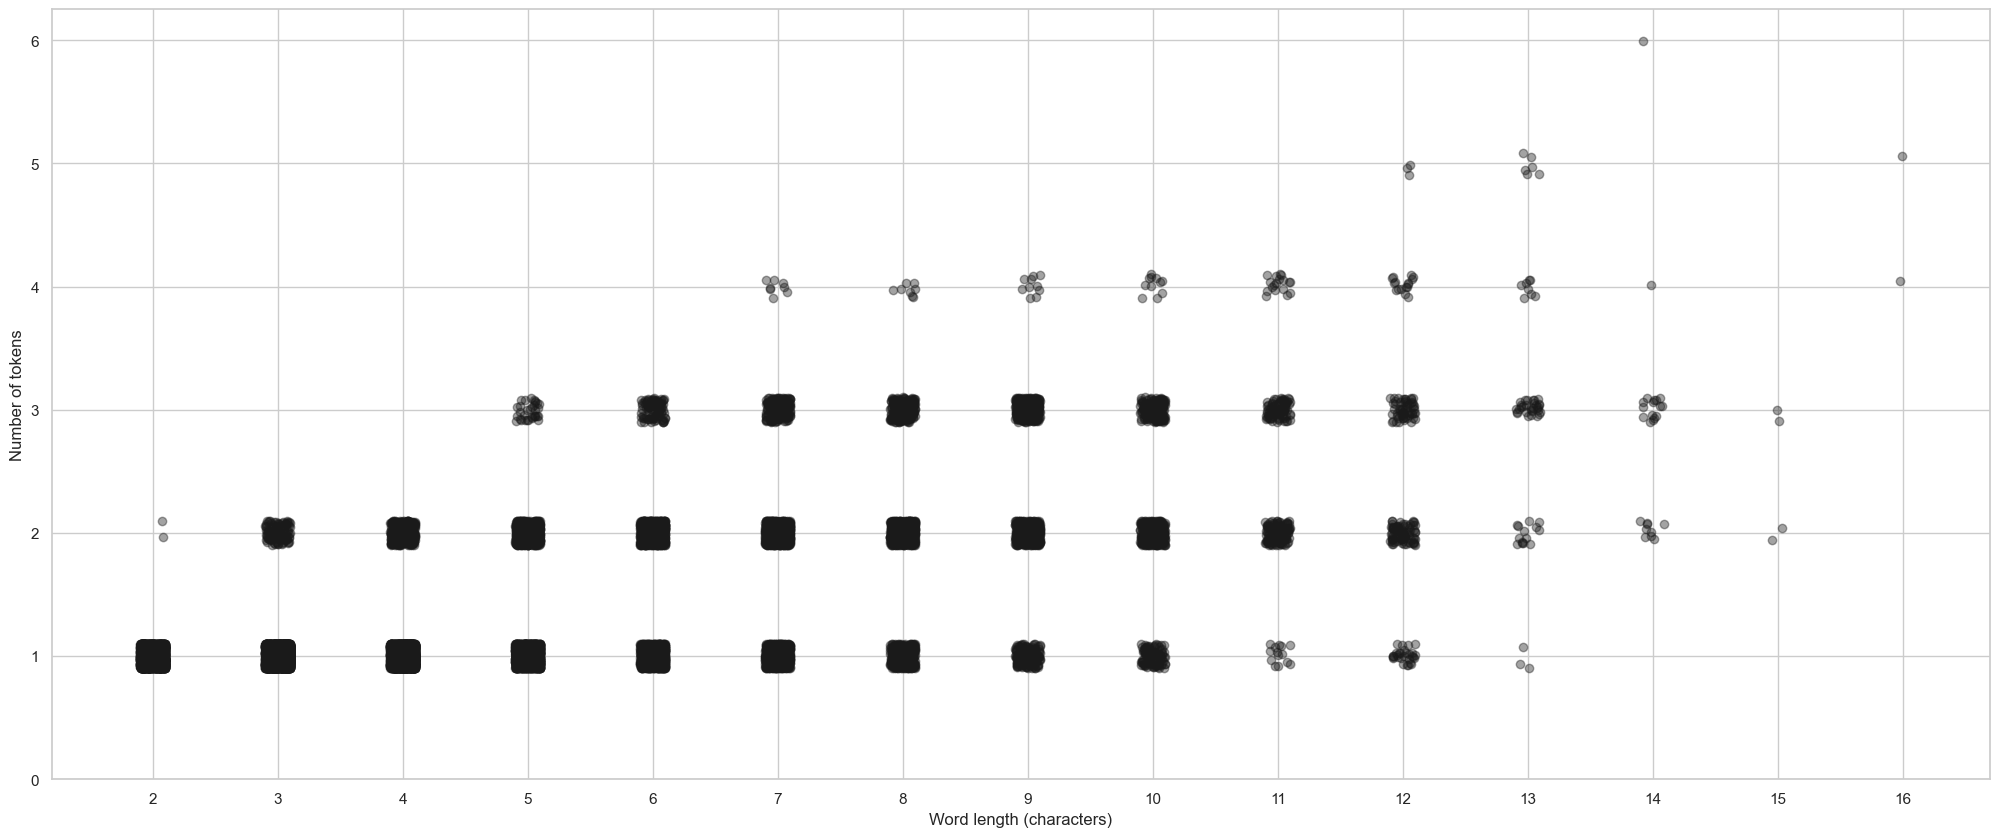

In [64]:
# adding jitter to the plot

plt.figure(figsize=(25, 10))
for length, counts in token_counts.items():
    lengths = [length]*len(counts)
    
    jitter_x = [length+np.random.uniform(-0.1, 0.1) for length in lengths]
    jitter_y = [count+np.random.uniform(-0.1, 0.1) for count in counts]
    
    plt.scatter(jitter_x, jitter_y, color="k", alpha=0.4)

plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens")
plt.xticks(sorted(token_counts.keys()))
largest = max([max(counts) for counts in token_counts.values()])
plt.yticks(range(largest+1));

In [65]:
max([max(counts) for counts in token_counts.values()])

6

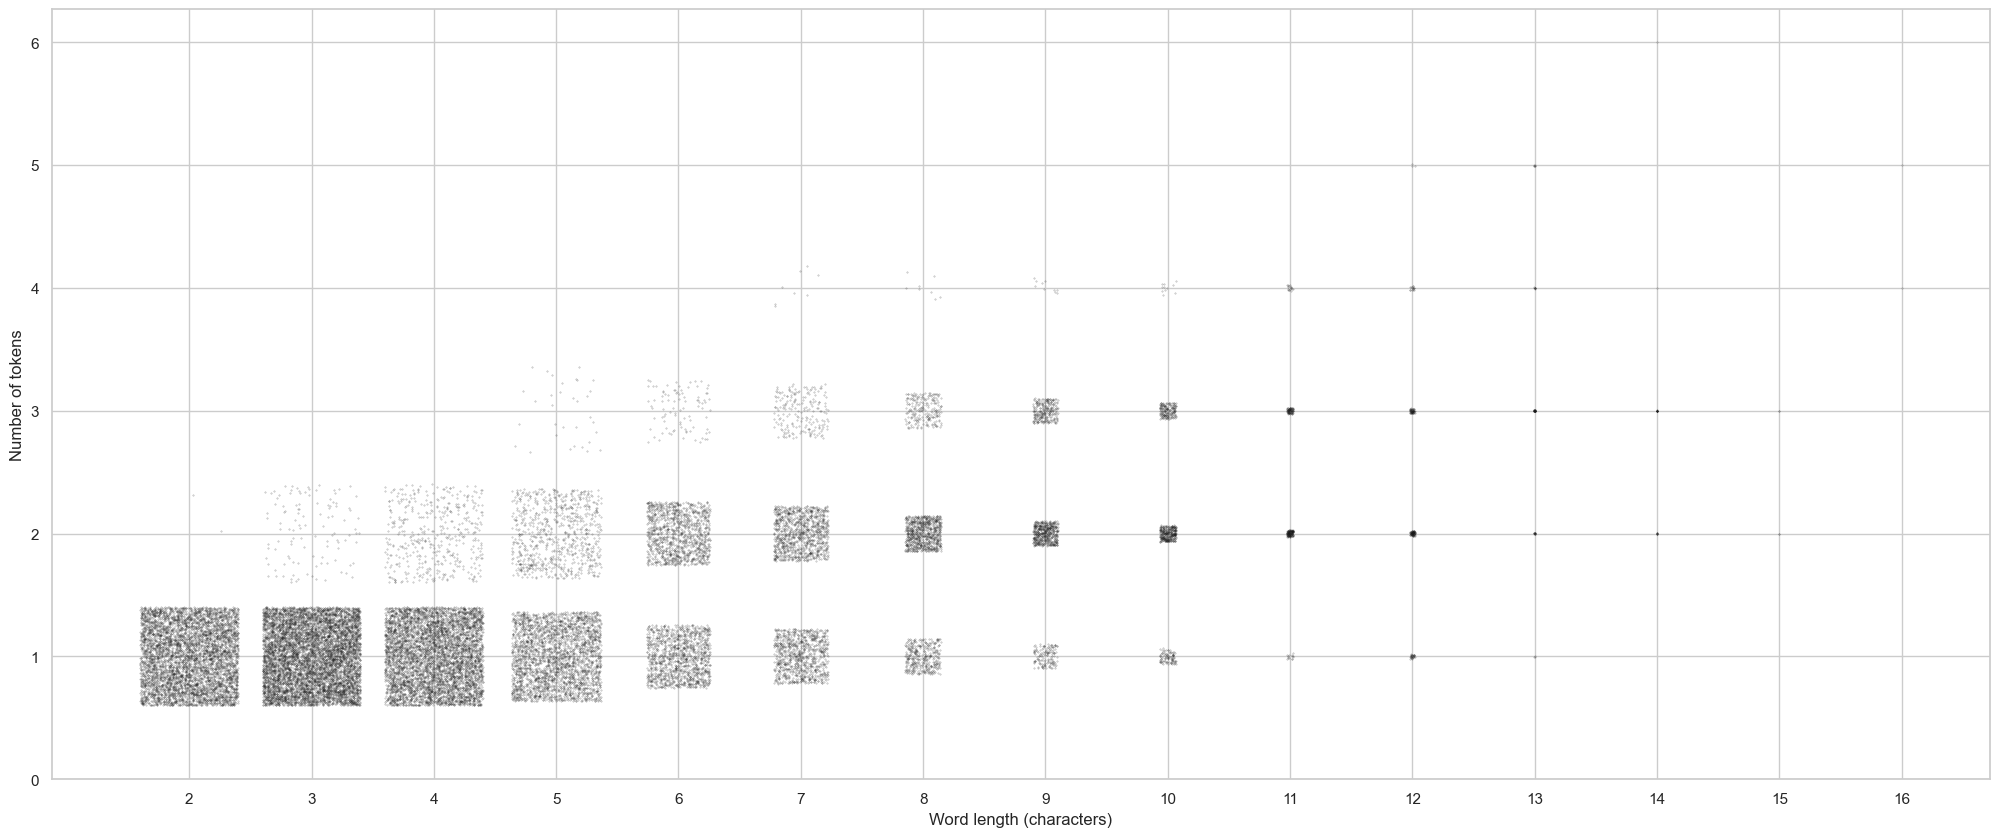

In [67]:
get_token_count = lambda word : len(tokenizer.encode(word))

token_counts = {}
for word in text:
    if len(word) not in token_counts.keys():
        token_counts[len(word)] = [get_token_count(word)]
    else:
        token_counts[len(word)].append(get_token_count(word))

word_counts = {k: len(v) for k, v in token_counts.items()}

plt.figure(figsize=(25, 10))
for length, counts in token_counts.items():
    lengths = [length]*len(counts)

    jitter_amount = min(0.4, word_counts[length] / 10000)    
    jitter_x = [length+np.random.uniform(-jitter_amount, jitter_amount) for length in lengths]
    jitter_y = [count+np.random.uniform(-jitter_amount, jitter_amount) for count in counts]
    
    plt.scatter(jitter_x, jitter_y, color="k", s=0.1, alpha=0.4)

plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens")
plt.xticks(sorted(token_counts.keys()))
largest = max([max(counts) for counts in token_counts.values()])
plt.yticks(range(largest+1));

In [68]:
len(token_counts[7])

2222

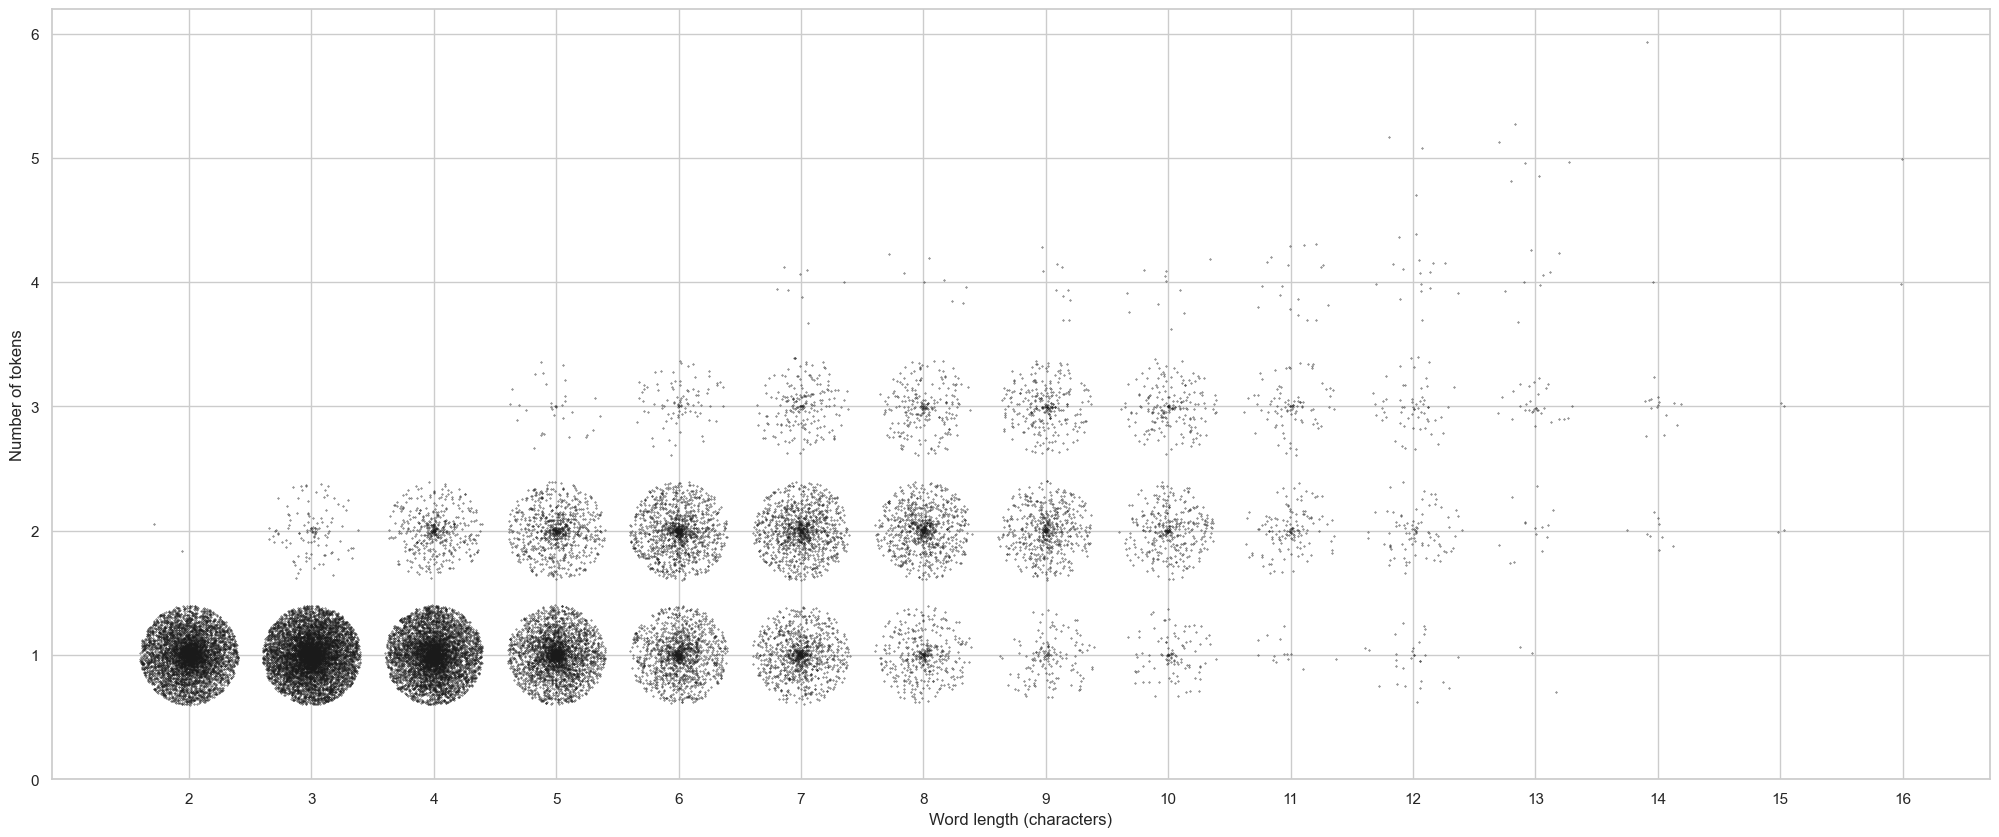

In [69]:
plt.figure(figsize=(25, 10))
for length, counts in token_counts.items():
    r = min(0.4, word_counts[length] / 100)
    
    jitter_x, jitter_y = [], []
    for count in counts:
        angle = np.random.uniform(0, 2*np.pi)
        radius = np.random.uniform(0, r)
        jitter_x.append(length + radius*np.cos(angle))
        jitter_y.append(count + radius*np.sin(angle))
    
    plt.scatter(jitter_x, jitter_y, color="k", s=0.1, alpha=1)

plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens")
plt.xticks(sorted(token_counts.keys()))
largest = max(max(c) for c in token_counts.values())
plt.yticks(range(largest+1))
plt.show()

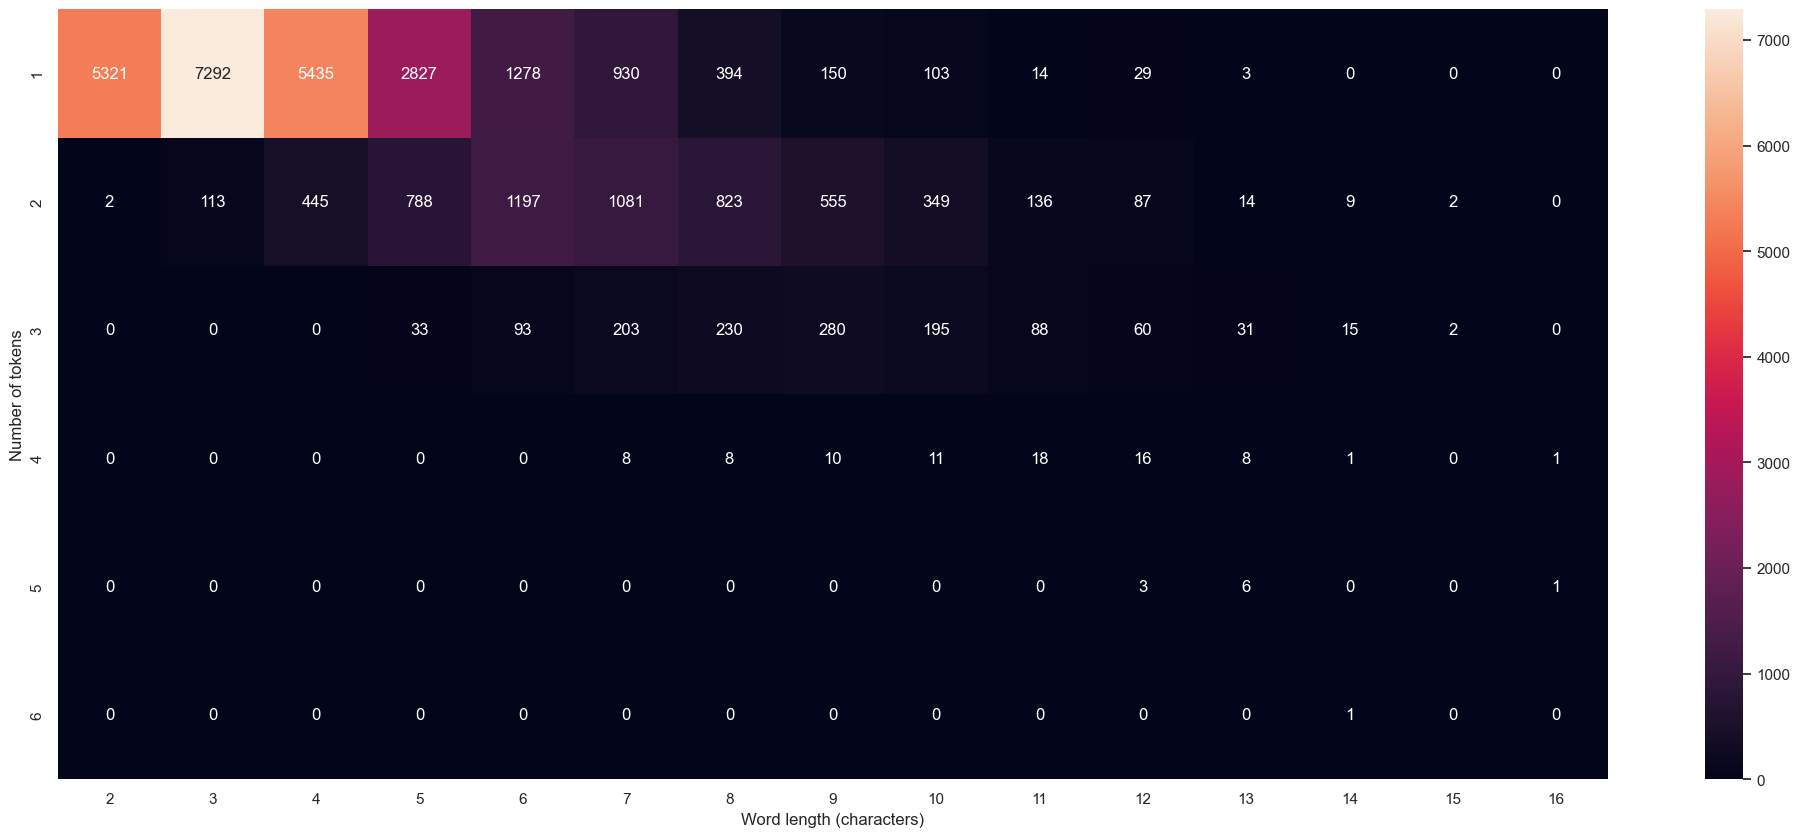

In [70]:
# heat map from scratch

word_lengths = sorted(set(len(word) for word in text))
n_tokens = sorted(set(len(tokenizer.encode(word)) for word in text))

def get_word_count(length, n_token):
    return sum([1 for word in text if (len(word)==length) and len(tokenizer.encode(word))==n_token])

token_counts = np.zeros((len(n_tokens), len(word_lengths)), dtype=int)

for row, n_token in enumerate(n_tokens):
    for col, length in enumerate(word_lengths):
        token_counts[row, col] = get_word_count(length, n_token)

plt.figure(figsize=(25, 10))
sns.heatmap(token_counts, annot=True, fmt="d", xticklabels=word_lengths, yticklabels=n_tokens)
plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens");

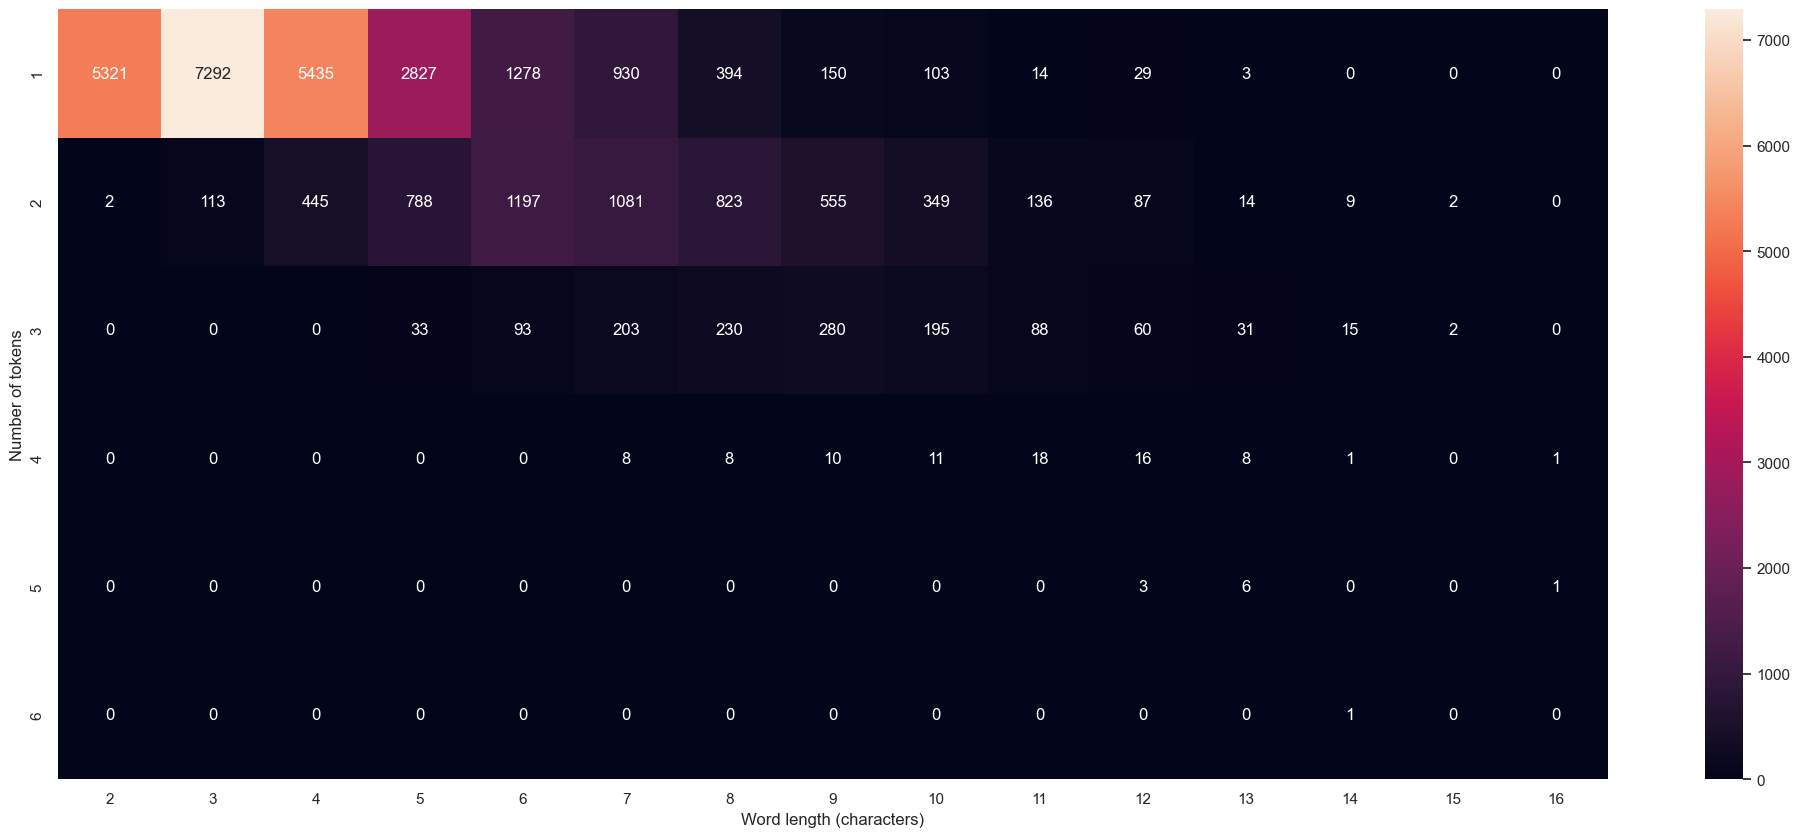

In [71]:


word_lengths = sorted(set(len(word) for word in text))
n_tokens = sorted(set(len(tokenizer.encode(word)) for word in text))

word_length_idx = {word_length: i for i, word_length in enumerate(word_lengths)}
token_idx = {n_token : i for i, n_token in enumerate(n_tokens)}

token_counts = np.zeros((len(n_tokens), len(word_lengths)), dtype=int)
for word in text:
    row = token_idx[len(tokenizer.encode(word))]
    col = word_length_idx[len(word)]
    token_counts[row, col] += 1
   

plt.figure(figsize=(25, 10))
sns.heatmap(token_counts, annot=True, fmt="d", xticklabels=word_lengths, yticklabels=n_tokens)
plt.xlabel("Word length (characters)")
plt.ylabel("Number of tokens");

In [72]:
# words that have more characters tend to have more tokens, but not generally the case
# general trend but noting is trivial

#### encoding of 14-character words

In [73]:
words_14_chars = [word for word in text if len(word)==14]

encode_seqs = [tokenizer.encode(word) for word in words_14_chars]
decode_seqs = [seq for seq in encode_seqs]

for word, decode_seq in zip(words_14_chars, decode_seqs):
    print(f"{word} comprises of {[tokenizer.decode([seq]) for seq in decode_seq]}")
    

intermittently comprises of ['inter', 'mitt', 'ently']
mathematicians comprises of ['math', 'ematic', 'ians']
investigations comprises of ['invest', 'ig', 'ations']
potentialities comprises of ['potential', 'ities']
incredibleness comprises of ['in', 'cred', 'ib', 'leness']
aforementioned comprises of ['a', 'fore', 'mentioned']
interpretation comprises of ['interpret', 'ation']
nebuchadnezzar comprises of ['ne', 'buch', 'ad', 'ne', 'zz', 'ar']
overwhelmingly comprises of ['over', 'whelming', 'ly']
disappointment comprises of ['dis', 'appointment']
interrogations comprises of ['inter', 'rog', 'ations']
conversational comprises of ['con', 'vers', 'ational']
characteristic comprises of ['character', 'istic']
specialisation comprises of ['special', 'isation']
interpretation comprises of ['interpret', 'ation']
interpretation comprises of ['interpret', 'ation']
expostulations comprises of ['ex', 'post', 'ulations']
differentiated comprises of ['different', 'iated']
stratification comprises o

In [74]:
[decode_seqs[0]]

[[2295, 24621, 4501]]

#### token efficiency

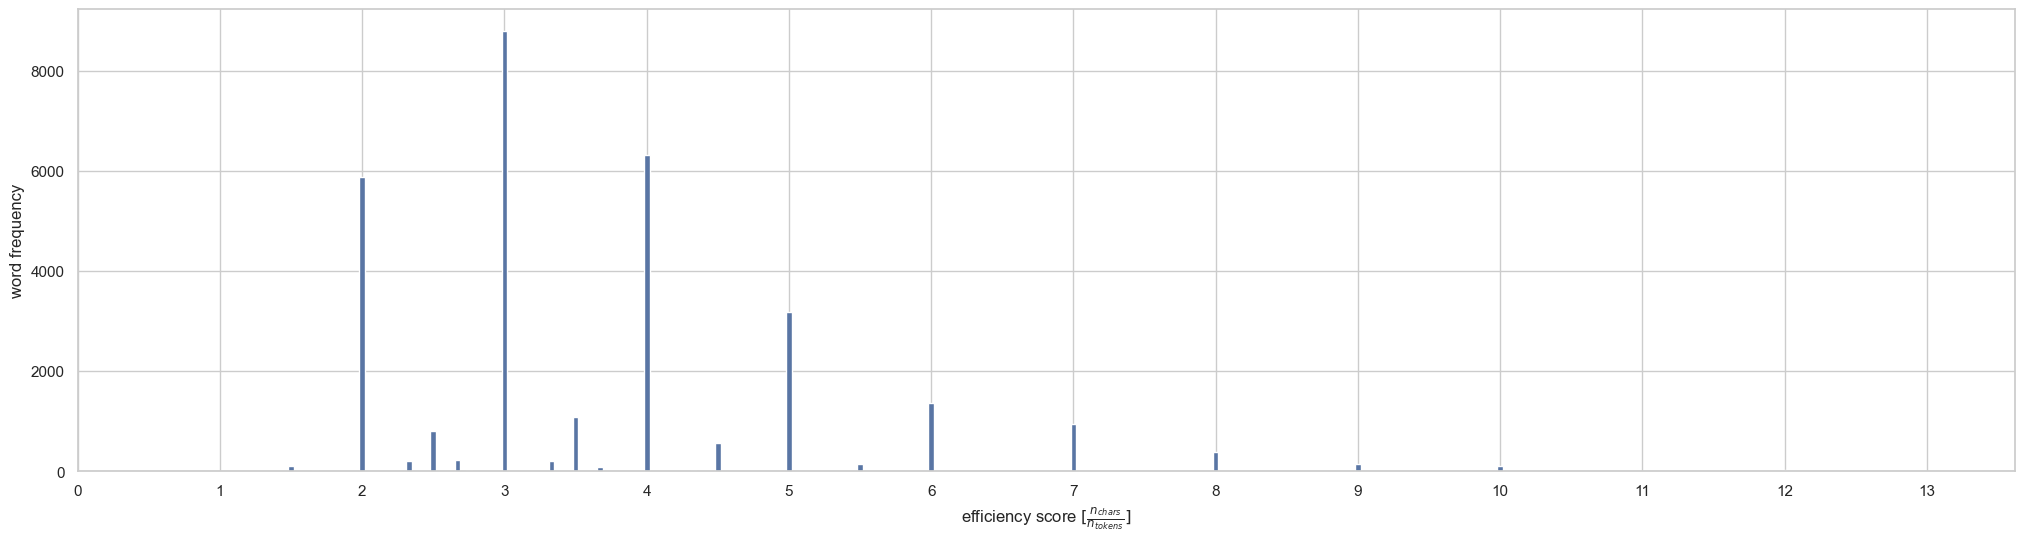

In [75]:
word_efficiencies = [round(len(word)/len(tokenizer.encode(word)), 2) for word in text]
frequencies = {x: word_efficiencies.count(x) for x in sorted(set(word_efficiencies))}

plt.figure(figsize=(25, 6))
sns.barplot(x=frequencies.keys(), y=frequencies.values(), native_scale=True)

max_val = int(max(frequencies.keys()))
plt.xticks(range(max_val+1))

plt.xlabel(r"efficiency score $[\frac{n_{chars}}{n_{tokens}}]$")
plt.ylabel("word frequency");

In [76]:
def get_words_from_efficiency(eff):
    return [word for word in text if len(word)/len(tokenizer.encode(word)) == eff]

max_, min_ = max(word_efficiencies), min(word_efficiencies)
print("Most efficient words: ")
print(f"{get_words_from_efficiency(max_)}")
print()
print("Least efficient words: ")
print(f"{get_words_from_efficiency(min_)}")

Most efficient words: 
['communication', 'advertisement', 'advertisement']

Least efficient words: 
['xv', 'xv']


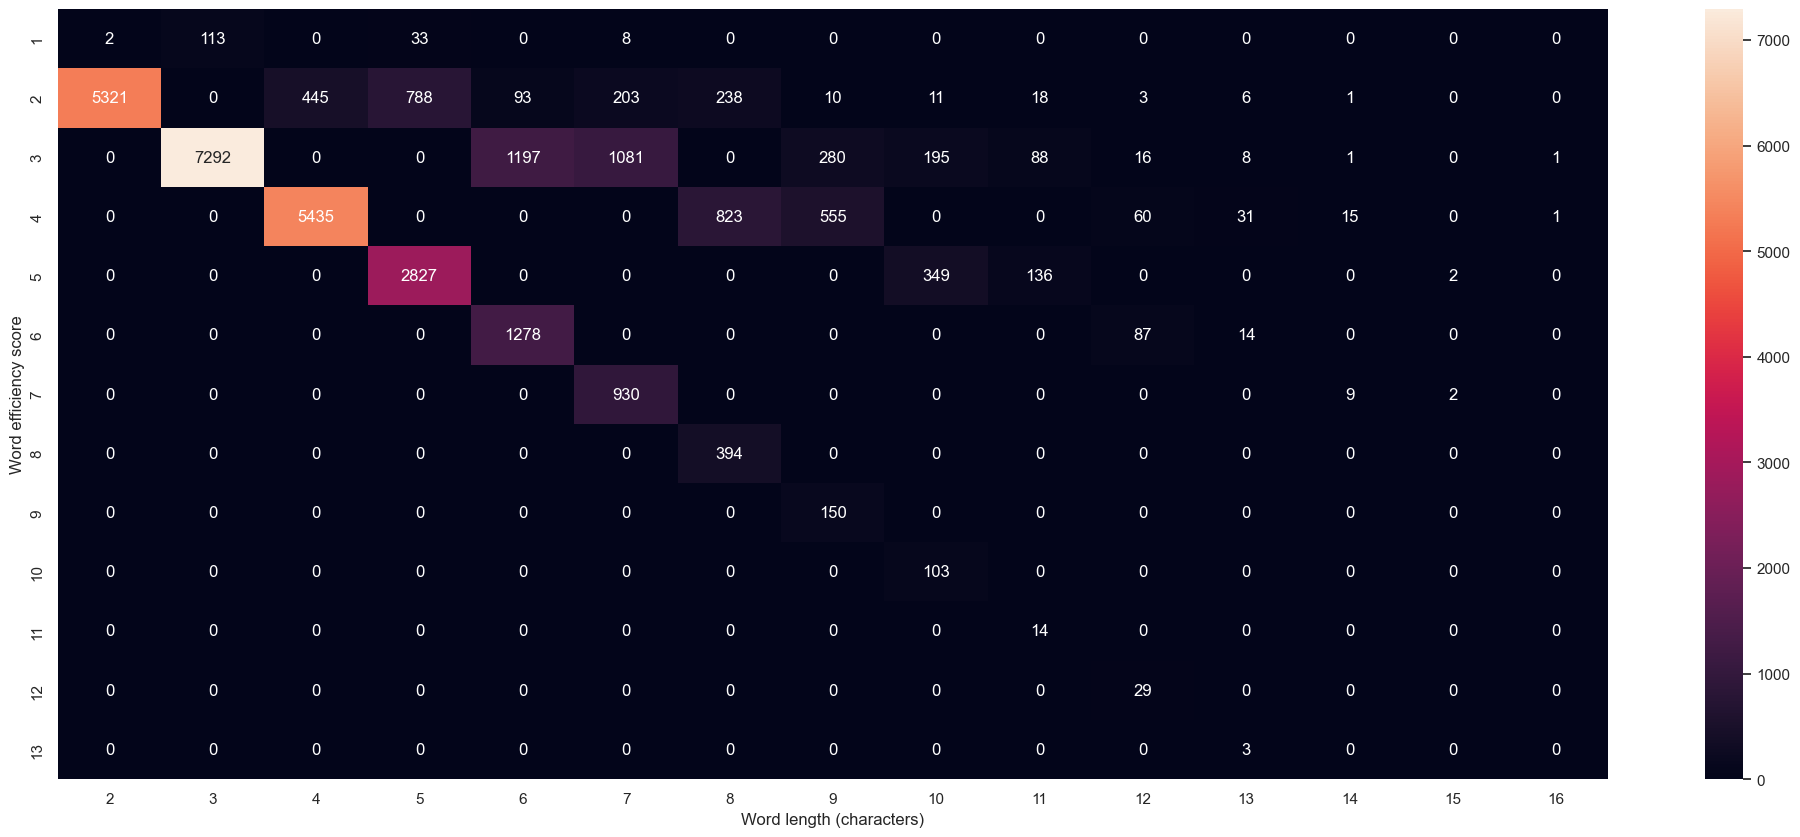

In [78]:
word_lengths = sorted(set(len(word) for word in text))
word_efficiencies = sorted(set(int(len(word)/len(tokenizer.encode(word))) for word in text))

length_idx = {l: i for i, l in enumerate(word_lengths)}
eff_idx = {e: i for i, e in enumerate(word_efficiencies)}

len_vs_eff = np.zeros((len(word_efficiencies), len(word_lengths)), dtype=int)

for word in text:
    length = len(word)
    eff = int(length / len(tokenizer.encode(word)))
    row = eff_idx[eff]
    col = length_idx[length]
    len_vs_eff[row, col] += 1

plt.figure(figsize=(25, 10))
sns.heatmap(len_vs_eff, annot=True, fmt="d", xticklabels=word_lengths, yticklabels=word_efficiencies)
plt.xlabel("Word length (characters)")
plt.ylabel("Word efficiency score")
plt.show()

#### tokens in separated words vs text

In [79]:
def get_context_word_level(word_seq, word2match, window=2):
    context = []
    for i, word in enumerate(word_seq):
        start = max(0, i-window)
        if word == word2match:
            context.append(" ".join(word_seq[start:i+window+1]))
    return context[:10] # restricted to the first 10 contexts

def get_context_token_level(token_seq, token2match, window=2): # almost similar to the above function
    contexts = []
    for i, token in enumerate(token_seq):
        start = max(0, i-window)
        if token == token2match:
            contexts.append(tokenizer.decode(token_seq[start:i+window+1]))
    return contexts[0:10] # restricted to the first 10 contexts

            

token_seq_entire_book = tokenizer.encode(" ".join(text))
random_idx = np.random.choice(token_seq_entire_book)
print(f"Token {random_idx} corresponds to `{tokenizer.decode([random_idx])}`\n")
print(get_context_token_level(token_seq_entire_book, token2match=random_idx, window=2))

Token 527 corresponds to ` are`

[' ideas that are almost universally', ' these things are mere ab', ' fact there are really four', ' my results are curious for', ' all these are evidently sections', ' traveller smiled are you so', ' man there are balloons but', ' where you are wrong that', ' wrong we are always getting', 'ences which are immaterial']


In [81]:

def get_context(word_seq, word2match, window=2):
    context = []
    for i, word in enumerate(word_seq):
        if word == word2match:
            pass

word_encodings = {word: tokenizer.encode(word) for word in text}
random_word = str(np.random.choice(list(word_encodings.keys())))
print(f"Random string `{random_word}` has encoding: `{word_encodings[random_word]}`\n")
print(get_context(text, word2match=random_word, window=2))

Random string `pallor` has encoding: `[79, 543, 269]`

None


In [107]:
text = requests.get("https://www.gutenberg.org/files/35/35-0.txt").text
text = preprocess(text)
print(len(text))
unique_words = sorted(set([word for word in text])) # vocab
print(f"# unique words = {len(unique_words)}")

30699
# unique words = 4589


In [108]:
def get_context(idx, window=5):
    start = max(0, idx-window)
    return tokenizer.decode(np.array(token_seq_entire_book)[start: idx+window])

# pick a random token from the first 10% of GPT4 tokens

token_seq_entire_book = tokenizer.encode(" ".join(text)) # encoding the entire book

random_idx = np.random.choice(sorted(set(token_seq_entire_book)))
decoded_word = tokenizer.decode([random_idx])
print(f"Token {random_idx} is `{decoded_word}`\n")

words_containing_token = [word for word in unique_words if random_idx in tokenizer.encode(word)] # both are correct (this does not use the decoded word)
print(f"Words containing the token: \n{words_containing_token}")

print("\n\n")

# where did the random token appear in the text? # context
idx = np.where(np.array(token_seq_entire_book) == random_idx)[0][0]
print(f"Context (window = 5): {get_context(idx, window=10)}")

Token 62130 is `lemn`

Words containing the token: 
['belemnite']



Context (window = 5):  had once seen done from the ink of fossil belemnite that must have perished and become fossil


In [109]:
idx

np.int64(24344)

In [110]:
print(tokenizer.encode("stagnant"))
print(tokenizer.encode(" stagnant"))

[267, 3326, 519]
[97043]


In [111]:
tokenizer.decode([519])

'ant'

In [112]:
print(tokenizer.encode("time"))
print(tokenizer.encode("the time traveller"))

[1712]
[1820, 892, 86294]


In [113]:
print(tokenizer.encode("rice cake"))
print(tokenizer.encode("racecar"))

[23994, 19692]
[42283, 7063]


#### word frequency versus encoding length

In [125]:
text = requests.get("https://www.gutenberg.org/files/35/35-0.txt").text
text = preprocess(text) # list
unique_words = sorted(set([word for word in text])) 
print(f"# unique words = {len(unique_words)}")

# unique words = 4589


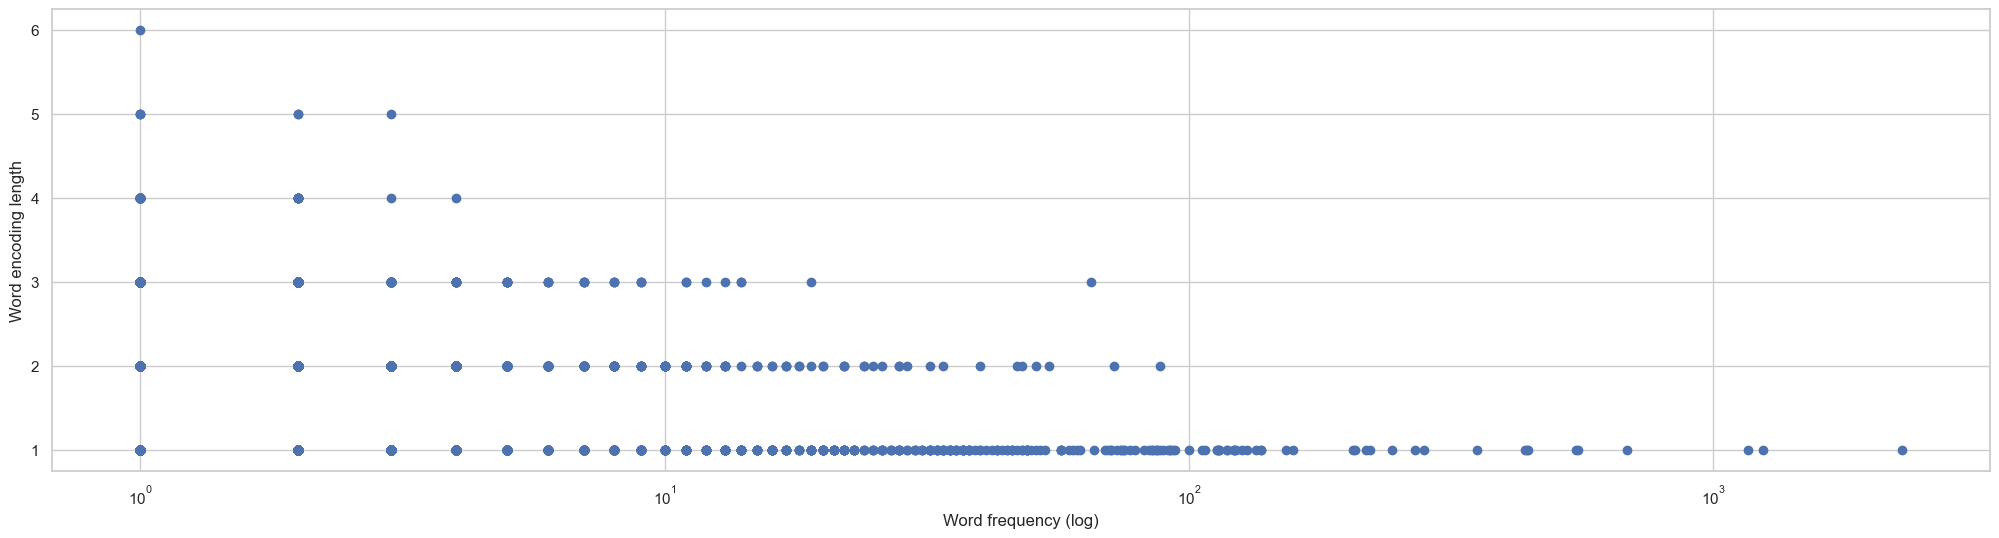

In [136]:
word_freq = {word : text.count(word) for word in unique_words}
num_tokens = {word: len(tokenizer.encode(word)) for word in unique_words}

plt.figure(figsize=(25, 6))
plt.scatter(word_freq.values(), num_tokens.values())
plt.xscale("log")
plt.xlabel("Word frequency (log)")
plt.ylabel("Word encoding length");

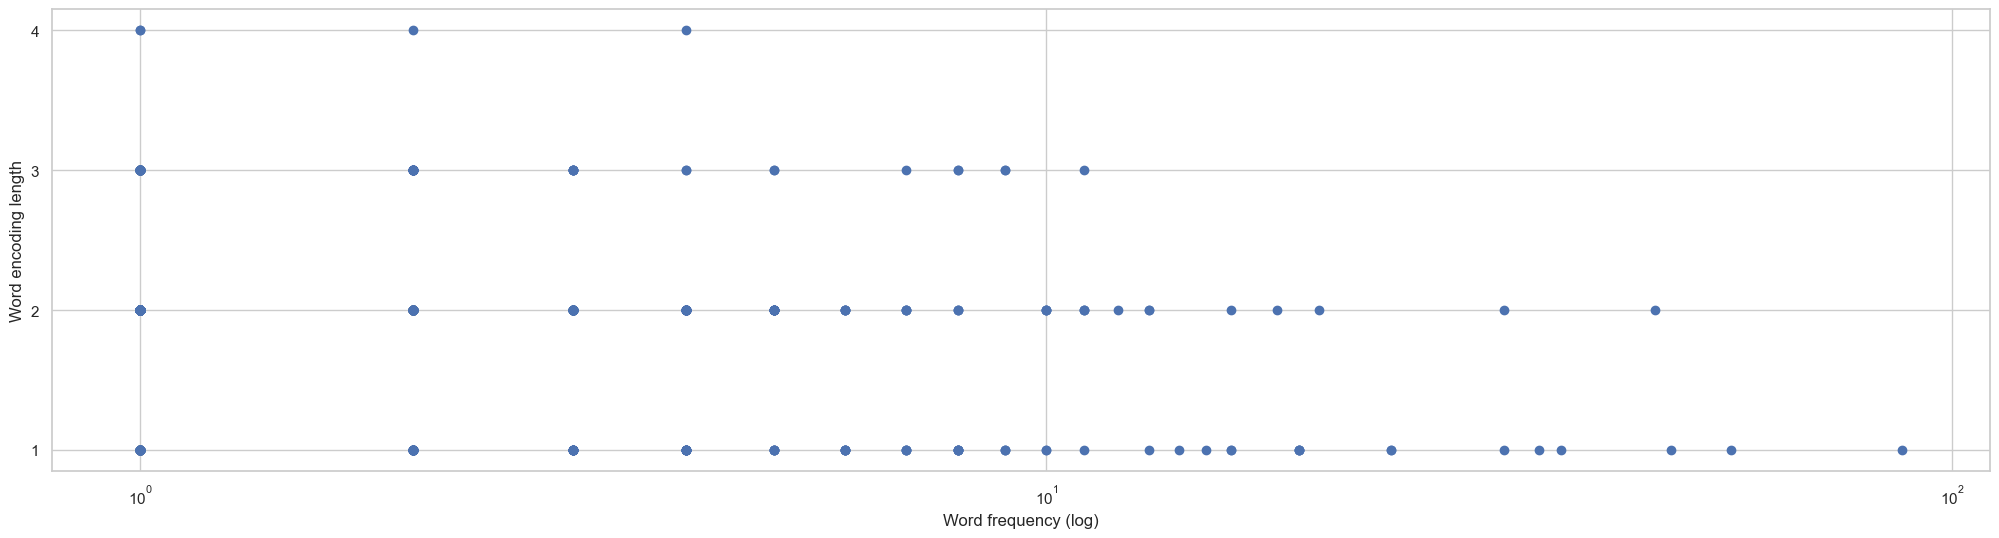

In [143]:
word_freq = {word : text.count(word) for word in unique_words}
num_tokens = {word: len(tokenizer.encode(word)) for word in unique_words}

def get_plot_for_word_length(word_length):
    x = [v for k, v in word_freq.items() if len(k) == word_length]
    y = [v for k, v in num_tokens.items() if len(k) == word_length]
    
    plt.figure(figsize=(25, 6))
    plt.scatter(x, y)
    plt.xscale("log")
    plt.xlabel("Word frequency (log)")
    plt.ylabel("Word encoding length")
    plt.yticks(range(1, max(y)+1))

get_plot_for_word_length(7)

#### fake words from real tokens

In [157]:
random_tokens = np.random.choice(tokenizer.n_vocab, 3)
tokenizer.decode(random_tokens)

'.completedroupon elseif'

## how many 'r' in the word strawberry

In [165]:
token_strawberry = tokenizer.encode("strawberry")
token_r = tokenizer.encode("r")

for t in token_strawberry:
    print(f"{t:5d} = {tokenizer.decode([t])}")

print()
for t in token_r:
    print(f"{t:5d} = {tokenizer.decode([t])}")

  496 = str
  675 = aw
15717 = berry

   81 = r


# BERT tokenizer

In [3]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

In [5]:
print(dir(tokenizer))

['SPECIAL_TOKENS_ATTRIBUTES', '__annotations__', '__bool__', '__call__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_add_bos_token', '_add_eos_token', '_add_tokens', '_added_tokens_decoder', '_added_tokens_encoder', '_auto_class', '_convert_encoding', '_convert_id_to_token', '_convert_token_to_id_with_added_voc', '_decode', '_encode_plus', '_eventual_warn_about_too_long_sequence', '_extra_special_tokens', '_from_pretrained', '_get_files_timestamps', '_get_padding_truncation_strategies', '_in_target_context_manager', '_pad', '_pad_token_type_id', '_patch_mistral_regex', '_post_init', '_processor_class', '_

In [19]:
all_tokens = list(tokenizer.get_vocab().keys())
print(all_tokens[10000: 10010])

print(len(all_tokens))
print(tokenizer.vocab_size)

tokenizer.get_vocab()["science"] # encoding the word science

['##tained', 'tonga', '##bari', 'vial', 'spitting', '1939', 'lesson', 'path', '5', 'seduction']
30522
30522


2671

### How to encode in BERT

#### two ways to tokenize

In [23]:
word = "science"

res1 = tokenizer.convert_tokens_to_ids(word)
print(res1)
res2 = tokenizer.get_vocab()[word]
print(res2)

2671
2671


#### encoding a text

In [26]:
text = "science is great"

res1 = tokenizer.convert_tokens_to_ids(text)
print(res1)
res2 = tokenizer.get_vocab()[text] # only works for individual tokens in the vocab
print(res2)

100


KeyError: 'science is great'

#### better way to encode

In [44]:
text = "science is great"

token_ids = tokenizer.encode(text)
print(token_ids)
print()

print(tokenizer.decode(token_ids))

print()
for token_id in token_ids:
    print(tokenizer.decode(token_id))

[101, 2671, 2003, 2307, 102]

[CLS] science is great [SEP]

[CLS]
science
is
great
[SEP]


In [48]:
text = "science is great"
tokens = tokenizer.tokenize(text)
tokenizer.convert_tokens_to_ids(tokens) # results in no special tokens

[2671, 2003, 2307]

In [42]:
# is it lossless encoder?

text = "science is great"
print(tokenizer.decode(tokenizer.encode(text)))
print(tokenizer.decode(tokenizer.encode(text), skip_special_tokens=True))

[CLS] science is great [SEP]
science is great


### another way to encode - using the class instance

In [43]:
text = "science is great"
tokenizer(text)

{'input_ids': [101, 2671, 2003, 2307, 102], 'token_type_ids': [0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1]}

In [51]:
text = "Science is great"
tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens) # results in no special tokens

tokenizer.decode(token_ids) # result of uncased BERT tokenizer; capitalization is completely eradicated

'science is great'

### Character frequencies in the BERT vocabulary

In [61]:
digits_letters = string.digits + string.ascii_lowercase

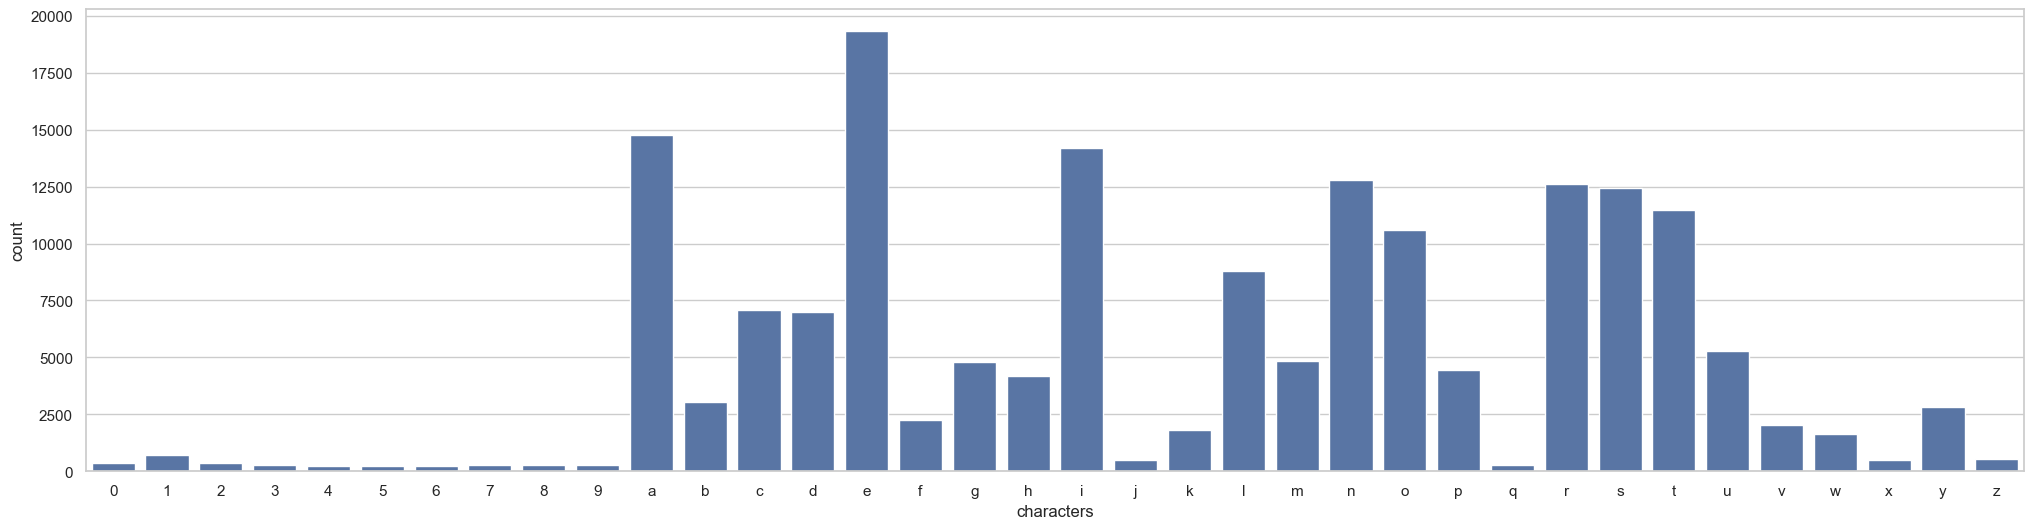

In [70]:
all_words = list(tokenizer.vocab.keys())

freq_arr = {x : sum([word.count(x) for word in all_words if "unused" not in word]) for x in digits_letters}

plt.figure(figsize=(25, 6))
sns.barplot(x=freq_arr.keys(), y=freq_arr.values())
plt.xlabel("characters")
plt.ylabel("count");

In [73]:
sorted(freq_arr.items(), key=lambda x : x[1], reverse=True)

[('e', 19326),
 ('a', 14759),
 ('i', 14184),
 ('n', 12772),
 ('r', 12629),
 ('s', 12447),
 ('t', 11470),
 ('o', 10576),
 ('l', 8774),
 ('c', 7066),
 ('d', 7014),
 ('u', 5271),
 ('m', 4854),
 ('g', 4807),
 ('p', 4455),
 ('h', 4169),
 ('b', 3025),
 ('y', 2816),
 ('f', 2270),
 ('v', 2028),
 ('k', 1793),
 ('w', 1632),
 ('1', 727),
 ('z', 533),
 ('x', 501),
 ('j', 476),
 ('0', 366),
 ('2', 344),
 ('8', 287),
 ('9', 283),
 ('7', 279),
 ('q', 276),
 ('3', 259),
 ('6', 250),
 ('5', 240),
 ('4', 228)]

### Working with two tokenizers (GPT-4 and BERT)

In [74]:
gpt4_tokenizer = tiktoken.get_encoding("cl100k_base")
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

In [89]:
text = "Hello, my name is Abhishek and I like the color yellow"
print(f"Original text: {text}")
print()
# encoding the text and getting the token ids
gpt4_tokens = gpt4_tokenizer.encode(text)
bert_tokens = bert_tokenizer.encode(text)

print(f"GPT4 tokens: {gpt4_tokens}")
print(f"Decoded using GPT4: {gpt4_tokenizer.decode(gpt4_tokens)}")
print(f"Decoded using BERT: {bert_tokenizer.decode(gpt4_tokens)}")
print()
print(f"BERT tokens: {bert_tokens}")
print(f"Decoded using GPT4: {gpt4_tokenizer.decode(bert_tokens)}")
print(f"Decoded using BERT: {bert_tokenizer.decode(bert_tokens)}")

Original text: Hello, my name is Abhishek and I like the color yellow

GPT4 tokens: [9906, 11, 856, 836, 374, 3765, 26301, 92180, 323, 358, 1093, 279, 1933, 14071]
Decoded using GPT4: Hello, my name is Abhishek and I like the color yellow
Decoded using BERT: lately [unused10] [unused851] [unused831] [unused369] cars schoolhouse [unused318] [unused353] ¾ [unused274] 竹 wan

BERT tokens: [101, 7592, 1010, 2026, 2171, 2003, 11113, 24158, 5369, 2243, 1998, 1045, 2066, 1996, 3609, 3756, 102]
Decoded using GPT4: �.deleteceptionrgretoin smooth %% addition�(idate	for.lengthunic device�
Decoded using BERT: [CLS] hello, my name is abhishek and i like the color yellow [SEP]


#### text translation

In [92]:
text = "Hello, my name is Abhishek and I like the color yellow"

gpt4_tokens = gpt4_tokenizer.encode(text)
gpt4_reconstructed_text = gpt4_tokenizer.decode(gpt4_tokens)

bert_tokens = bert_tokenizer.encode(gpt4_reconstructed_text)
bert_tokenizer.decode(bert_tokens, skip_special_tokens=True)

'hello, my name is abhishek and i like the color yellow'

#### text compression

In [98]:
text = '''Natural language processing has changed dramatically over the past few decades, evolving from rigid rule-based systems in the 1960s to statistical machine learning approaches in the 1990s, and eventually to today's massive neural architectures. Early systems relied on hand-crafted grammars and dictionaries, which worked reasonably well for narrow domains but couldn't generalize to the messiness of real-world language. The shift toward statistical methods — think n-gram models, hidden Markov models, and later support vector machines — allowed researchers to learn patterns directly from data rather than encoding them by hand. Tokenization itself has undergone a similar transformation: where early pipelines simply split text on whitespace and punctuation, modern subword tokenizers like WordPiece, BPE, and SentencePiece can handle out-of-vocabulary words, morphological variants, and even multilingual text by breaking unfamiliar words into smaller, reusable pieces. For instance, a word like "unbelievably" might decompose into "un", "believ", "ably", while a rare technical term such as "electroencephalography" could fragment into five or six subword units, depending on the tokenizer's vocabulary size (30,000 for BERT, roughly 100,000 for GPT-4's cl100k_base, or upward of 200,000 for newer encodings like o200k_base). This isn't just a technical curiosity — it directly affects computational cost, since more tokens per sentence means longer sequences, higher memory usage, and slower inference. By 2026, most production NLP systems, whether for search, translation, or conversational AI, treat tokenization as a foundational preprocessing step rather than an afterthought, and understanding its mechanics — encoder/decoder logic, merge rules, vocabulary construction, and edge cases like leading-space effects — remains essential for anyone building or debugging these pipelines from scratch.'''
print(f"# characters: {len(text)}")
print(f"# GPT4 tokens: {len(gpt4_tokenizer.encode(text))}")
print(f"# BERT tokens: {len(bert_tokenizer.encode(text))}")

# characters: 1907
# GPT4 tokens: 378
# BERT tokens: 414


In [108]:
text = "start\r\n\r\n\n\r\r\r\r\n\t\t\t\t\t\t\nend"
print(f"Original text:\n{text}")
print("-"*50)

gpt4_tokens = gpt4_tokenizer.encode(text)
bert_tokens = bert_tokenizer.encode(text)

print(f"Decoded using GPT4: {gpt4_tokenizer.decode(gpt4_tokens)}")
print("-"*50)
print(f"Decoded using BERT: {bert_tokenizer.decode(bert_tokens)}")

Original text:
start



						
end
--------------------------------------------------
Decoded using GPT4: start



						
end
--------------------------------------------------
Decoded using BERT: [CLS] start end [SEP]


### Translating token IDs between tokenizers

In [113]:
gpt4_tokenizer = tiktoken.get_encoding("cl100k_base")
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

def bert2gpt4(bert_tokens):
    return gpt4_tokenizer.encode(bert_tokenizer.decode(bert_tokens, skip_special_tokens=True))
    
def gpt42bert(gpt4_tokens):
    return bert_tokenizer.encode(gpt4_tokenizer.decode(gpt4_tokens), add_special_tokens=False)

In [114]:
text = "The flow of ink is smooth."

print(bert2gpt4(bert_tokenizer.encode(text)))
print(gpt42bert(gpt4_tokenizer.encode(text)))

[1820, 6530, 315, 27513, 374, 11113, 13]
[1996, 4834, 1997, 10710, 2003, 5744, 1012]


In [126]:
# BERT-> GPT4 -> BERT

sentence = "Natural language processing has evolved rapidly, moving from rule-based systems to statistical models and now to transformer-based neural networks that power today's language technologies."

bert_tokenizer.decode(gpt42bert(bert2gpt4(bert_tokenizer.encode(sentence))))

"natural language processing has evolved rapidly, moving from rule - based systems to statistical models and now to transformer - based neural networks that power today ' s language technologies."

In [127]:
# GPT4 -> BERT-> GPT4

sentence = "Natural language processing has evolved rapidly, moving from rule-based systems to statistical models and now to transformer-based neural networks that power today's language technologies."

gpt4_tokenizer.decode(bert2gpt4(gpt42bert(gpt4_tokenizer.encode(sentence))))

"natural language processing has evolved rapidly, moving from rule - based systems to statistical models and now to transformer - based neural networks that power today ' s language technologies."

## Token compression ratio across books

In [157]:
# all books have the same url format;
# they are unique by numerical code
baseurl = 'https://www.gutenberg.org/files/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'    ],
    ['64317', 'GreatGatsby'     ],
    ['11',    'AliceWonderland' ],
    ['1513',  'RomeoJuliet'     ],
    ['76',    'HuckFinn'        ],
    ['219',   'HeartDarkness'   ],
    ['2591',  'GrimmsTales'     ],
    ['2148',  'EdgarAllenPoe'   ],
    ['36',    'WarOfTheWorlds'  ],
    ['829',   'GulliversTravels']
]

tokenizer = tiktoken.get_encoding('cl100k_base')

res = {"Book Title": [], "Characters": [], "Tokens": [], "Compression (%)": []}
for code, title in bookurls:
    book = requests.get(f"{baseurl}{code}/{code}-0.txt")
    text = book.text
    res["Book Title"].append(title)
    res["Characters"].append(len(text))
    res["Tokens"].append(len(tokenizer.encode(text)))
    compression = 100*(len(tokenizer.encode(text))/len(text))
    res["Compression (%)"].append(round(compression, 2))

res_df = pd.DataFrame(res)
res_df

,Book Title,Characters,Tokens,Compression (%)
0,Frankenstein,419434,98003,23.37
1,GreatGatsby,270822,65403,24.15
2,AliceWonderland,144696,36958,25.54
3,RomeoJuliet,142570,39450,27.67
4,HuckFinn,571153,153613,26.90
5,HeartDarkness,213353,52404,24.56
6,GrimmsTales,549750,137271,24.97
7,EdgarAllenPoe,602212,139887,23.23
8,WarOfTheWorlds,337521,80278,23.78
9,GulliversTravels,582513,139220,23.90


#### repeat with websites

In [180]:
weburls = [
    'http://python.org/',
    'https://pytorch.org/',
    'https://en.wikipedia.org/wiki/List_of_English_words_containing_Q_not_followed_by_U',
    'https://sudoku.com/',
    'https://reddit.com/',
    'https://visiteurope.com/en/',
    'https://sincxpress.com/',
    'https://openai.com/',
    'https://theuselessweb.com/',
    'https://maps.google.com/',
    'https://pigeonsarentreal.co.uk/',
]

res = {"Website": [], "Characters": [], "Tokens": [], "Compression (%)": []}
for url in weburls:
    text = requests.get(url).text
    res["Website"].append(urlparse(url).hostname)
    res["Characters"].append(len(text))
    res["Tokens"].append(len(tokenizer.encode(text)))
    compression = 100*(len(tokenizer.encode(text))/len(text))
    res["Compression (%)"].append(round(compression, 2))

res_df = pd.DataFrame(res)
res_df

,Website,Characters,Tokens,Compression (%)
0,python.org,52741,13869,26.30
1,pytorch.org,207935,63877,30.72
2,en.wikipedia.org,126,34,26.98
3,sudoku.com,150126,53645,35.73
4,reddit.com,8393,3224,38.41
5,visiteurope.com,285942,94416,33.02
6,sincxpress.com,25392,7123,28.05
7,openai.com,9679,5074,52.42
8,theuselessweb.com,6119,1667,27.24
9,maps.google.com,209959,111576,53.14


In [178]:
for url in weburls:
    print(urlparse(url).hostname)

python.org
pytorch.org
en.wikipedia.org
sudoku.com
reddit.com
visiteurope.com
sincxpress.com
openai.com
theuselessweb.com
maps.google.com
pigeonsarentreal.co.uk


In [179]:
url.split("//")[1].split(".")[0]

'pigeonsarentreal'

#### repeat with string attributes

In [196]:
string.__dict__["__all__"]

['ascii_letters',
 'ascii_lowercase',
 'ascii_uppercase',
 'capwords',
 'digits',
 'hexdigits',
 'octdigits',
 'printable',
 'punctuation',
 'whitespace',
 'Formatter',
 'Template']

In [192]:
string.__dict__.keys()

dict_keys(['__name__', '__doc__', '__package__', '__loader__', '__spec__', '__file__', '__cached__', '__builtins__', '__all__', '_string', 'whitespace', 'ascii_lowercase', 'ascii_uppercase', 'ascii_letters', 'digits', 'hexdigits', 'octdigits', 'punctuation', 'printable', 'capwords', '_re', '_ChainMap', '_sentinel_dict', 'Template', 'Formatter'])

In [205]:
res = {"String Attribute": [], "Characters": [], "Tokens": [], "Compression (%)": []}
for k, v in string.__dict__.items():
    if isinstance(v, str) and len(v) > 0:
        text = v
        res["String Attribute"].append(k)
        res["Characters"].append(len(text))
        res["Tokens"].append(len(tokenizer.encode(text)))
        compression = 100*(len(tokenizer.encode(text))/len(text))
        res["Compression (%)"].append(round(compression, 2))

res_df = pd.DataFrame(res)
res_df

,String Attribute,Characters,Tokens,Compression (%)
0,__name__,6,1,16.67
1,__doc__,622,109,17.52
2,__file__,48,17,35.42
3,__cached__,73,27,36.99
4,whitespace,6,4,66.67
5,ascii_lowercase,26,1,3.85
6,ascii_uppercase,26,1,3.85
7,ascii_letters,52,2,3.85
8,digits,10,4,40.00
9,hexdigits,22,7,31.82


## Tokenization is not always compression

In [213]:
english = "The cat and the dog both wanted the same sunny spot on the mat, so they had a very slow staring contest until the cat won by falling asleep first."
spanish = "El gato y el perro querían el mismo lugar soleado en la alfombra, así que tuvieron un concurso de miradas muy lento hasta que el gato ganó quedándose dormido primero."
french = "Le chat et le chien voulaient tous les deux la même place ensoleillée sur le tapis, alors ils ont eu un concours de regard très lent jusqu'à ce que le chat gagne en s'endormant le premier."
german = "Die Katze und der Hund wollten beide denselben sonnigen Platz auf der Matte, also hatten sie einen sehr langsamen Starrwettbewerb, bis die Katze gewann, indem sie zuerst einschlief."
italian = "Il gatto e il cane volevano entrambi lo stesso posto soleggiato sul tappeto, così hanno avuto una gara di sguardi molto lenta finché il gatto non ha vinto addormentandosi per primo."
portuguese = "O gato e o cachorro queriam o mesmo lugar ensolarado no tapete, então tiveram uma disputa de olhar muito lenta até que o gato venceu adormecendo primeiro."
hindi = "बिल्ली और कुत्ता दोनों चटाई पर उसी धूप वाली जगह को चाहते थे, इसलिए उनके बीच एक बहुत धीमी घूरने की प्रतियोगिता हुई जब तक कि बिल्ली पहले सो जाने से जीत नहीं गई।"
japanese = "猫と犬は両方ともマットの上の同じ日向の場所を欲しがったので、猫が先に眠ってしまって勝つまで、とてもゆっくりとにらめっこをした。"
mandarin = "猫和狗都想要垫子上同一个阳光充足的位置,于是它们进行了一场非常缓慢的瞪眼比赛,直到猫先睡着而获胜。"
russian = "Кошка и собака обе хотели одно и то же солнечное место на коврике, поэтому у них был очень медленный конкурс гляделок, пока кошка не победила, заснув первой."
arabic = "أراد القط والكلب كلاهما نفس المكان المشمس على السجادة، لذا خاضا مسابقة تحديق بالنظر بطيئة جدًا حتى فاز القط بالنوم أولاً."

languages = {
    'english': english, 'spanish': spanish, 'french': french, 'german': german,
    'italian': italian, 'portuguese': portuguese, 'hindi': hindi,
    'japanese': japanese, 'mandarin': mandarin, 'russian': russian, 'arabic': arabic
}

gpt4_tokenizer = tiktoken.get_encoding("cl100k_base")
bert_tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

res = {"Language": [], "Characters": [], "GPT4": [], "BERT": []}
for language, text in languages.items():
    res["Language"].append(language.capitalize())
    res["Characters"].append(len(text))
    res["GPT4"].append(len(gpt4_tokenizer.encode(text)))
    res["BERT"].append(len(bert_tokenizer.encode(text, add_special_tokens=False)))
    
res_df = pd.DataFrame(res)
res_df

,Language,Characters,GPT4,BERT
0,English,146,32,32
1,Spanish,166,48,56
2,French,188,52,62
3,German,181,49,64
4,Italian,181,56,62
5,Portuguese,154,46,56
6,Hindi,158,158,95
7,Japanese,63,70,63
8,Mandarin,49,70,49
9,Russian,157,77,126


## Zipf's law

### Intro

In [230]:
np.random.seed(42)
nums = np.random.randint(-2, 5, 20)
print(nums)
uniques, counts = np.unique(nums, return_counts=True)
print(uniques)
print()
for n, c in zip(uniques, counts):
    print(f"{n} appears {c} times")

[ 4  1  2  4  0  2  2  4 -1  0  4  0  0  2  1  0  3  2 -1  1]
[-1  0  1  2  3  4]

-1 appears 2 times
0 appears 5 times
1 appears 3 times
2 appears 5 times
3 appears 1 times
4 appears 4 times


In [234]:
text = '''The old lighthouse keeper hummed quietly to himself as the fog rolled in from the sea.'''

uniques, counts = np.unique(list(text), return_counts=True)
print(uniques)
print()
for n, c in zip(uniques, counts):
    print(f"{n} appears {c} times")

[' ' '.' 'T' 'a' 'd' 'e' 'f' 'g' 'h' 'i' 'k' 'l' 'm' 'n' 'o' 'p' 'q' 'r'
 's' 't' 'u' 'y']

  appears 15 times
. appears 1 times
T appears 1 times
a appears 2 times
d appears 3 times
e appears 12 times
f appears 3 times
g appears 2 times
h appears 7 times
i appears 4 times
k appears 1 times
l appears 6 times
m appears 4 times
n appears 1 times
o appears 6 times
p appears 1 times
q appears 1 times
r appears 3 times
s appears 4 times
t appears 5 times
u appears 3 times
y appears 1 times


In [239]:
text = '''The old lighthouse keeper hummed quietly to himself as the fog rolled in from the sea.'''

freq_char = {char: text.count(char) for char in set(text)}

sorted(freq_char.items(), key=lambda x:x[1], reverse=True)

[(' ', 15),
 ('e', 12),
 ('h', 7),
 ('l', 6),
 ('o', 6),
 ('t', 5),
 ('i', 4),
 ('m', 4),
 ('s', 4),
 ('r', 3),
 ('f', 3),
 ('d', 3),
 ('u', 3),
 ('g', 2),
 ('a', 2),
 ('n', 1),
 ('y', 1),
 ('.', 1),
 ('q', 1),
 ('T', 1),
 ('p', 1),
 ('k', 1)]

In [294]:
def get_rank_and_counts(arr):
    uniques, counts = np.unique(arr, return_counts=True)
    return sorted(zip(uniques, counts), key=lambda x: x[1], reverse=True)

text = '''The old lighthouse keeper hummed quietly to himself as the fog rolled in from the sea.'''

get_rank_and_counts(list(text))

[(np.str_(' '), np.int64(15)),
 (np.str_('e'), np.int64(12)),
 (np.str_('h'), np.int64(7)),
 (np.str_('l'), np.int64(6)),
 (np.str_('o'), np.int64(6)),
 (np.str_('t'), np.int64(5)),
 (np.str_('i'), np.int64(4)),
 (np.str_('m'), np.int64(4)),
 (np.str_('s'), np.int64(4)),
 (np.str_('d'), np.int64(3)),
 (np.str_('f'), np.int64(3)),
 (np.str_('r'), np.int64(3)),
 (np.str_('u'), np.int64(3)),
 (np.str_('a'), np.int64(2)),
 (np.str_('g'), np.int64(2)),
 (np.str_('.'), np.int64(1)),
 (np.str_('T'), np.int64(1)),
 (np.str_('k'), np.int64(1)),
 (np.str_('n'), np.int64(1)),
 (np.str_('p'), np.int64(1)),
 (np.str_('q'), np.int64(1)),
 (np.str_('y'), np.int64(1))]

### On books

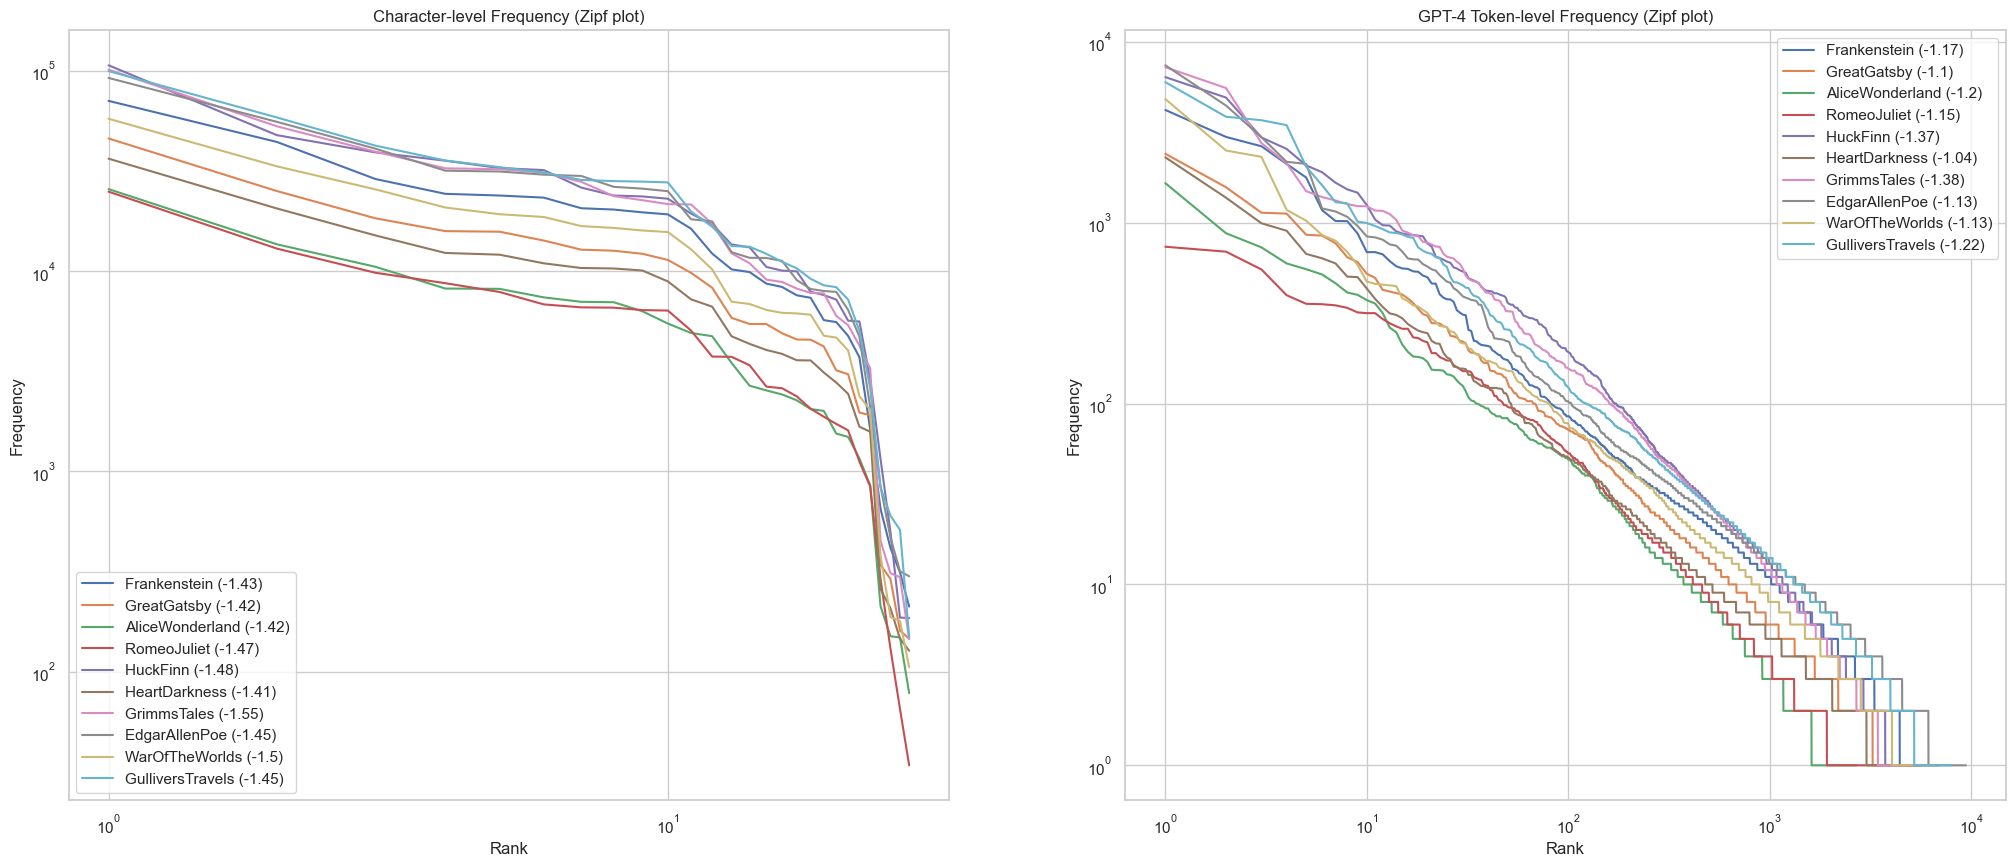

In [312]:
def do_regression(X, y):
    return round(LinearRegression().fit(np.expand_dims(X, 1), y).coef_[0], 2)

def get_freq_arr(arr):
    freq = {item: arr.count(item) for item in set(arr)}
    freq_sorted = sorted(freq.items(), key=lambda x: x[1], reverse=True)
    rank_labels = [item[0] for item in freq_sorted]
    ranks = range(1, len(freq_sorted)+1)
    counts = [item[1] for item in freq_sorted]
    return ranks, counts
    
tokenizer = tiktoken.get_encoding('cl100k_base')

baseurl = 'https://www.gutenberg.org/files/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'    ],
    ['64317', 'GreatGatsby'     ],
    ['11',    'AliceWonderland' ],
    ['1513',  'RomeoJuliet'     ],
    ['76',    'HuckFinn'        ],
    ['219',   'HeartDarkness'   ],
    ['2591',  'GrimmsTales'     ],
    ['2148',  'EdgarAllenPoe'   ],
    ['36',    'WarOfTheWorlds'  ],
    ['829',   'GulliversTravels']
]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 10))

for code, title in bookurls:
    book = requests.get(f"{baseurl}{code}/{code}-0.txt")
    text = book.text
    text = " ".join(preprocess(text))
    token_ids = tokenizer.encode(text)
    
    x, y = get_freq_arr(list(text))
    slope = do_regression(np.log10(x), np.log10(y))
    ax[0].plot(x, y, label=f"{title} ({slope})")
    ax[0].set_xscale("log")
    ax[0].set_yscale("log")
    ax[0].legend()
    ax[0].set_xlabel("Rank")
    ax[0].set_ylabel("Frequency")
    ax[0].set_title("Character-level Frequency (Zipf plot)")
    

    
    x, y = get_freq_arr(token_ids)
    slope = do_regression(np.log10(x), np.log10(y))
    ax[1].plot(x, y, label=f"{title} ({slope})")
    ax[1].set_xscale("log")
    ax[1].set_yscale("log")
    ax[1].legend()
    ax[1].set_xlabel("Rank")
    ax[1].set_ylabel("Frequency")
    ax[1].set_title("GPT-4 Token-level Frequency (Zipf plot)")
plt.savefig("zipfs_law_empirical_check.png", dpi=150, bbox_inches="tight")

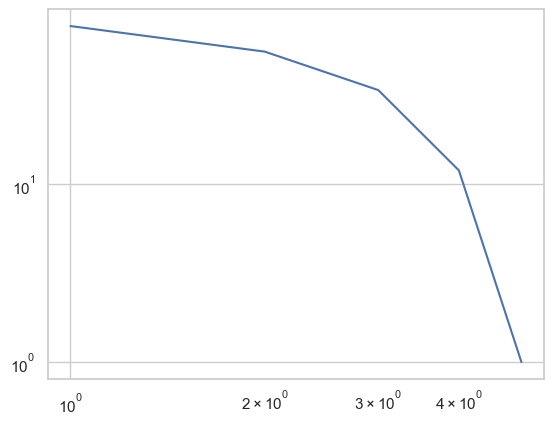

In [307]:

counts = [78, 56, 34, 12, 1]
ranks = [i for i in range(1, len(counts)+1)]

plt.loglog(ranks, counts)

### Claude tokenizer

In [32]:
tokenizer = GPT2TokenizerFast.from_pretrained('Xenova/claude-tokenizer')

In [33]:
tokenizer.vocab_size

65000

In [34]:
text = "the flow of ink is smooth"
tokenizer.encode(text)

[1264, 4229, 316, 25967, 365, 10705]

In [35]:
tokenizer(text, return_tensors="pt")

{'input_ids': tensor([[ 1264,  4229,   316, 25967,   365, 10705]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1]])}

#### some examples of multitoken words

In [46]:
words = ["hypothetical", " hypothetical", "hypothetical ", "hypothteical", " hypothteical "]

for word in words:
    tokens = tokenizer.encode(word)
    decoded = [tokenizer.decode(token) for token in tokens]
    print(f"{word:15} --> {tokens} :: {decoded}")
    print()

hypothetical    --> [30678, 36881] :: ['hypot', 'hetical']

 hypothetical   --> [44086] :: [' hypothetical']

hypothetical    --> [30678, 36881, 225] :: ['hypot', 'hetical', ' ']

hypothteical    --> [32851, 1309, 384, 709] :: ['hyp', 'oth', 'te', 'ical']

 hypothteical   --> [18806, 1309, 384, 709, 225] :: [' hyp', 'oth', 'te', 'ical', ' ']



In [52]:
words = ["can't", " can't", "cant"]

for word in words:
    tokens = tokenizer.encode(word)
    decoded = [tokenizer.decode(token) for token in tokens]
    print(f"{word:15} --> {tokens} :: {decoded}")
    print()

can't           --> [3152, 828] :: ['can', "'t"]

 can't          --> [689, 828] :: [' can', "'t"]

cant            --> [25918] :: ['cant']



In [49]:
words = [" straight forward", " straightforward", "straight-forward"]

for word in words:
    tokens = tokenizer.encode(word)
    decoded = [tokenizer.decode(token) for token in tokens]
    print(f"{word:15} --> {tokens} :: {decoded}")
    print()

 straight forward --> [7638, 4258] :: [' straight', ' forward']

 straightforward --> [29388] :: [' straightforward']

straight-forward --> [48854, 17, 6978] :: ['straight', '-', 'forward']



In [53]:
words = ["parttime", " part-time", "part-time"]

for word in words:
    tokens = tokenizer.encode(word)
    decoded = [tokenizer.decode(token) for token in tokens]
    print(f"{word:15} --> {tokens} :: {decoded}")
    print()

parttime        --> [1620, 793] :: ['part', 'time']

 part-time      --> [919, 17, 793] :: [' part', '-', 'time']

part-time       --> [1620, 17, 793] :: ['part', '-', 'time']



In [54]:
words = [
    "receive receeve",
    "separate seperate",
    "definitely definately",
    "necessary neccessary",
]

for word in words:
    tokens = tokenizer.encode(word)
    decoded = [tokenizer.decode(token) for token in tokens]
    print(f"{word:15} --> {tokens} :: {decoded}")
    print()

receive receeve --> [19787, 2255, 40164] :: ['receive', ' rece', 'eve']

separate seperate --> [45670, 40622, 353] :: ['separate', ' seper', 'ate']

definitely definately --> [531, 23444, 39887, 2704] :: ['def', 'initely', ' defin', 'ately']

necessary neccessary --> [20960, 718, 2358, 658] :: ['necessary', ' ne', 'ccess', 'ary']

